## Women's General and Mental Health Analysis

##### Dataset: CDC BRFSS 2023
##### Sample: 229,523 female respondents
##### Tools: Python, Pandas, Matplotlib, Seaborn, SciPy, Statsmodels

### Objective

##### To explore how demographic, socioeconomic, and lifestyle characteristics are associated with self-reported general health and poor mental-health days among women.

In [216]:
import pandas as pd

df = pd.read_sas(
    "Data/Raw/LLCP2023.XPT",
    format="xport"
)

In [217]:
df.shape

(433323, 350)

In [218]:
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,b'03012023',b'03',b'01',b'2023',1100.0,b'2023000001',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,b'01062023',b'01',b'06',b'2023',1100.0,b'2023000002',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,b'03082023',b'03',b'08',b'2023',1100.0,b'2023000003',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,b'03062023',b'03',b'06',b'2023',1100.0,b'2023000004',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,b'01062023',b'01',b'06',b'2023',1100.0,b'2023000005',2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [219]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 433323 entries, 0 to 433322
Columns: 350 entries, _STATE to _DRNKDRV
dtypes: float64(345), object(5)
memory usage: 1.1+ GB


In [220]:
variables = [
    "_SEX", "_AGEG5YR", "_RACEGR3",
    "EDUCA", "INCOME3", "MARITAL", "_CHLDCNT",
    "EXERANY2", "_SMOKER3", "_DRNKWK2",
    "_BMI5", "_BMI5CAT",
    "MENTHLTH", "GENHLTH", "SDHSTRE1"
]

for var in variables:
    print(var, var in df.columns)

_SEX True
_AGEG5YR True
_RACEGR3 True
EDUCA True
INCOME3 True
MARITAL True
_CHLDCNT True
EXERANY2 True
_SMOKER3 True
_DRNKWK2 True
_BMI5 True
_BMI5CAT True
MENTHLTH True
GENHLTH True
SDHSTRE1 True


In [221]:
women_health = df[variables].copy()

In [222]:
women_health.shape

(433323, 15)

In [223]:
women_health.info()

<class 'pandas.DataFrame'>
RangeIndex: 433323 entries, 0 to 433322
Data columns (total 15 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   _SEX      433323 non-null  float64
 1   _AGEG5YR  433323 non-null  float64
 2   _RACEGR3  433237 non-null  float64
 3   EDUCA     433314 non-null  float64
 4   INCOME3   425248 non-null  float64
 5   MARITAL   433316 non-null  float64
 6   _CHLDCNT  433323 non-null  float64
 7   EXERANY2  433321 non-null  float64
 8   _SMOKER3  433323 non-null  float64
 9   _DRNKWK2  433323 non-null  float64
 10  _BMI5     392788 non-null  float64
 11  _BMI5CAT  392788 non-null  float64
 12  MENTHLTH  433320 non-null  float64
 13  GENHLTH   433319 non-null  float64
 14  SDHSTRE1  223493 non-null  float64
dtypes: float64(15)
memory usage: 49.6 MB


In [224]:
women_health.head(20)

,_SEX,_AGEG5YR,_RACEGR3,EDUCA,INCOME3,MARITAL,_CHLDCNT,EXERANY2,_SMOKER3,_DRNKWK2,_BMI5,_BMI5CAT,MENTHLTH,GENHLTH,SDHSTRE1
0,2.0,13.0,1.0,5.0,99.0,1.0,1.0,2.0,4.0,5.397605e-79,3047.0,4.0,88.0,2.0,5.0
1,2.0,13.0,1.0,5.0,99.0,2.0,1.0,1.0,4.0,5.397605e-79,2856.0,3.0,88.0,2.0,5.0
2,2.0,13.0,2.0,4.0,2.0,3.0,1.0,1.0,3.0,5.397605e-79,2231.0,2.0,2.0,4.0,3.0
3,2.0,12.0,1.0,5.0,99.0,1.0,1.0,1.0,4.0,5.397605e-79,2744.0,3.0,88.0,2.0,5.0
4,2.0,12.0,1.0,5.0,7.0,3.0,1.0,1.0,4.0,4.700000e+01,2585.0,3.0,88.0,4.0,2.0
5,2.0,9.0,2.0,5.0,7.0,3.0,1.0,1.0,4.0,2.330000e+02,3018.0,4.0,3.0,3.0,3.0
6,1.0,13.0,1.0,4.0,6.0,3.0,1.0,2.0,3.0,5.397605e-79,2441.0,2.0,77.0,4.0,5.0
7,2.0,12.0,2.0,5.0,99.0,3.0,1.0,2.0,4.0,5.397605e-79,2727.0,3.0,88.0,4.0,5.0
8,2.0,13.0,2.0,5.0,6.0,3.0,1.0,2.0,4.0,5.397605e-79,3347.0,4.0,88.0,3.0,4.0
9,1.0,12.0,1.0,4.0,7.0,1.0,1.0,1.0,3.0,5.397605e-79,2296.0,2.0,88.0,3.0,4.0


In [225]:
women_health = women_health[women_health["_SEX"] == 2.0].copy()

women_health = women_health.reset_index(drop=True)

women_health.insert(0, "ID", range(1, len(women_health)+ 1))

In [226]:
women_health.shape
women_health["ID"].is_unique

True

In [227]:
women_health.head()

,ID,_SEX,_AGEG5YR,_RACEGR3,EDUCA,INCOME3,MARITAL,_CHLDCNT,EXERANY2,_SMOKER3,_DRNKWK2,_BMI5,_BMI5CAT,MENTHLTH,GENHLTH,SDHSTRE1
0,1,2.0,13.0,1.0,5.0,99.0,1.0,1.0,2.0,4.0,5.397605e-79,3047.0,4.0,88.0,2.0,5.0
1,2,2.0,13.0,1.0,5.0,99.0,2.0,1.0,1.0,4.0,5.397605e-79,2856.0,3.0,88.0,2.0,5.0
2,3,2.0,13.0,2.0,4.0,2.0,3.0,1.0,1.0,3.0,5.397605e-79,2231.0,2.0,2.0,4.0,3.0
3,4,2.0,12.0,1.0,5.0,99.0,1.0,1.0,1.0,4.0,5.397605e-79,2744.0,3.0,88.0,2.0,5.0
4,5,2.0,12.0,1.0,5.0,7.0,3.0,1.0,1.0,4.0,4.700000e+01,2585.0,3.0,88.0,4.0,2.0


In [228]:
women_health.shape

(229523, 16)

In [229]:
women_health.info()

<class 'pandas.DataFrame'>
RangeIndex: 229523 entries, 0 to 229522
Data columns (total 16 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   ID        229523 non-null  int64  
 1   _SEX      229523 non-null  float64
 2   _AGEG5YR  229523 non-null  float64
 3   _RACEGR3  229483 non-null  float64
 4   EDUCA     229517 non-null  float64
 5   INCOME3   225365 non-null  float64
 6   MARITAL   229518 non-null  float64
 7   _CHLDCNT  229523 non-null  float64
 8   EXERANY2  229522 non-null  float64
 9   _SMOKER3  229523 non-null  float64
 10  _DRNKWK2  229523 non-null  float64
 11  _BMI5     201225 non-null  float64
 12  _BMI5CAT  201225 non-null  float64
 13  MENTHLTH  229522 non-null  float64
 14  GENHLTH   229521 non-null  float64
 15  SDHSTRE1  119803 non-null  float64
dtypes: float64(15), int64(1)
memory usage: 28.0 MB


In [230]:
women_health["GENHLTH"].value_counts(dropna=False).sort_index()

GENHLTH
1.0    31822
2.0    76164
3.0    76005
4.0    33933
5.0    11042
7.0      394
9.0      161
NaN        2
Name: count, dtype: int64

In [231]:
women_health["MENTHLTH"].value_counts(dropna=False).sort_index()

MENTHLTH
1.0       7935
2.0      13891
3.0       9125
4.0       4477
5.0      12178
6.0       1244
7.0       4687
8.0        982
9.0        136
10.0      9526
11.0        73
12.0       645
13.0        91
14.0      1753
15.0      8837
16.0       166
17.0       110
18.0       177
19.0        26
20.0      5655
21.0       303
22.0        80
23.0        62
24.0        57
25.0      1921
26.0        65
27.0       107
28.0       549
29.0       209
30.0     15232
77.0      3274
88.0    124831
99.0      1118
NaN          1
Name: count, dtype: int64

In [232]:
for col in women_health.columns:
    if col != "ID":
        print("\n", col)
        print(women_health[col].value_counts(dropna=False).sort_index())


 _SEX
_SEX
2.0    229523
Name: count, dtype: int64

 _AGEG5YR
_AGEG5YR
1.0     11340
2.0     10069
3.0     12299
4.0     13967
5.0     14669
6.0     14315
7.0     16836
8.0     18174
9.0     22486
10.0    24989
11.0    23770
12.0    19232
13.0    23053
14.0     4324
Name: count, dtype: int64

 _RACEGR3
_RACEGR3
1.0    166091
2.0     19329
3.0     11879
4.0      5156
5.0     22724
9.0      4304
NaN        40
Name: count, dtype: int64

 EDUCA
EDUCA
1.0      327
2.0     4114
3.0     8113
4.0    53729
5.0    63668
6.0    98434
9.0     1132
NaN        6
Name: count, dtype: int64

 INCOME3
INCOME3
1.0      5452
2.0      5882
3.0      7582
4.0     11003
5.0     22211
6.0     25872
7.0     29909
8.0     24657
9.0     24446
10.0    11091
11.0    11109
77.0    22146
99.0    24005
NaN      4158
Name: count, dtype: int64

 MARITAL
MARITAL
1.0    111237
2.0     31697
3.0     34952
4.0      4647
5.0     35190
6.0      9599
9.0      2196
NaN         5
Name: count, dtype: int64

 _CHLDCNT
_CHLDCNT
1.

## Clean 1 : Special Missing Codes

In [233]:
clean_health = women_health.copy()

In [234]:
import numpy as np

In [235]:
missing_codes = {
    "_AGEG5YR": [14],
    "_RACEGR3": [9],
    "EDUCA": [9],
    "INCOME3": [77, 99],
    "MARITAL": [9],
    "_CHLDCNT": [9],
    "EXERANY2": [7, 9],
    "_SMOKER3": [9],
    "_DRNKWK2": [99900],
    "MENTHLTH": [77, 99],
    "GENHLTH": [7, 9],
    "SDHSTRE1": [7, 9]
}

In [236]:
for column, codes in missing_codes.items():
    clean_health[column] = clean_health[column].replace(codes, np.nan)

In [237]:
clean_health.isna().sum()

ID               0
_SEX             0
_AGEG5YR      4324
_RACEGR3      4344
EDUCA         1138
INCOME3      50309
MARITAL       2201
_CHLDCNT      4304
EXERANY2       616
_SMOKER3     12001
_DRNKWK2     16676
_BMI5        28298
_BMI5CAT     28298
MENTHLTH      4393
GENHLTH        557
SDHSTRE1    110358
dtype: int64

In [238]:
clean_health["MENTHLTH"] = clean_health["MENTHLTH"].replace(88, 0)

In [239]:
clean_health["MENTHLTH"].value_counts(dropna = False).sort_index()

MENTHLTH
0.0     124831
1.0       7935
2.0      13891
3.0       9125
4.0       4477
5.0      12178
6.0       1244
7.0       4687
8.0        982
9.0        136
10.0      9526
11.0        73
12.0       645
13.0        91
14.0      1753
15.0      8837
16.0       166
17.0       110
18.0       177
19.0        26
20.0      5655
21.0       303
22.0        80
23.0        62
24.0        57
25.0      1921
26.0        65
27.0       107
28.0       549
29.0       209
30.0     15232
NaN       4393
Name: count, dtype: int64

In [240]:
clean_health["_BMI5"] = clean_health["_BMI5"] / 100

In [241]:
clean_health["_BMI5"].value_counts(dropna = False).sort_index()

_BMI5
12.02        2
12.09        1
12.11        2
12.12        1
12.22        1
         ...  
96.56        1
97.25        1
97.65        2
99.79        1
NaN      28298
Name: count, Length: 3402, dtype: int64

In [242]:
clean_health["_DRNKWK2"] = clean_health["_DRNKWK2"] / 100

In [243]:
clean_health[["_BMI5", "_DRNKWK2"]].describe()

,_BMI5,_DRNKWK2
count,201225.000000,2.128470e+05
mean,28.413594,1.760938e+00
std,7.064328,5.240220e+00
min,12.020000,5.397605e-81
25%,23.440000,5.397605e-81
50%,27.260000,5.397605e-81
75%,31.930000,1.400000e+00
max,99.790000,5.320000e+02


In [244]:
clean_health.loc[clean_health["_DRNKWK2"] < 0.001, "_DRNKWK2"] = 0

In [245]:
clean_health["_DRNKWK2"].min()

np.float64(0.0)

## Clean 2 : Duplicate Rows

In [246]:
clean_health.duplicated().sum()

np.int64(0)

In [247]:
clean_health.drop(columns="ID").duplicated().sum()

np.int64(2734)

In [248]:
"_STATE" in df.columns, "SEQNO" in df.columns

(True, True)

In [249]:
df[["_STATE", "SEQNO"]].duplicated().sum()

np.int64(0)

In [250]:
clean_health.shape

(229523, 16)

#* The combination of _STATE and SEQNO identified no duplicate records in the original dataset. However, after selecting 15 variables and restricting the dataset to 229,523 female respondents, 2,734 rows had identical values across the selected variables (excluding the newly generated ID). These rows were retained because identical values across a subset of variables do not necessarily indicate duplicate respondents.

## Clean 3 : Invalid/Implausible values and Outliers

In [251]:
clean_health[["_BMI5", "_DRNKWK2", "MENTHLTH"]].describe()

,_BMI5,_DRNKWK2,MENTHLTH
count,201225.000000,212847.000000,225130.000000
mean,28.413594,1.760938,4.959561
std,7.064328,5.240220,8.692996
min,12.020000,0.000000,0.000000
25%,23.440000,0.000000,0.000000
50%,27.260000,0.000000,0.000000
75%,31.930000,1.400000,5.000000
max,99.790000,532.000000,30.000000


In [252]:
clean_health["_BMI5"].nlargest(10)

35100     99.79
89569     97.65
163093    97.65
100038    97.25
98100     96.56
194098    94.47
215980    94.02
56882     91.82
153713    91.55
117258    91.02
Name: _BMI5, dtype: float64

In [253]:
clean_health["_DRNKWK2"].nlargest(10)

9136      532.0
205131    532.0
27521     420.0
103849    420.0
51070     300.0
60861     280.0
225087    280.0
159922    252.0
73573     210.0
82812     210.0
Name: _DRNKWK2, dtype: float64

In [254]:
clean_health["_BMI5"].quantile([0.95, 0.99, 0.999, 1])

0.950    41.63
0.990    50.90
0.999    66.56
1.000    99.79
Name: _BMI5, dtype: float64

In [255]:
clean_health["_DRNKWK2"].quantile([0.95, 0.99, 0.995, 0.999, 1])

0.950      9.0
0.990     21.0
0.995     25.2
0.999     49.0
1.000    532.0
Name: _DRNKWK2, dtype: float64

In [256]:
clean_health[
    (clean_health["MENTHLTH"] < 0 ) |
    (clean_health["MENTHLTH"] > 30 )
]

,ID,_SEX,_AGEG5YR,_RACEGR3,EDUCA,INCOME3,MARITAL,_CHLDCNT,EXERANY2,_SMOKER3,_DRNKWK2,_BMI5,_BMI5CAT,MENTHLTH,GENHLTH,SDHSTRE1


In [257]:
categorical_vars = [
    "_AGEG5YR", "_RACEGR3", "EDUCA", "INCOME3",
    "MARITAL", "_CHLDCNT", "EXERANY2",
    "_SMOKER3", "_BMI5CAT", "GENHLTH", "SDHSTRE1"
]

for col in categorical_vars:
    print("\n", col)
    print(clean_health[col].value_counts(dropna=False).sort_index())


 _AGEG5YR
_AGEG5YR
1.0     11340
2.0     10069
3.0     12299
4.0     13967
5.0     14669
6.0     14315
7.0     16836
8.0     18174
9.0     22486
10.0    24989
11.0    23770
12.0    19232
13.0    23053
NaN      4324
Name: count, dtype: int64

 _RACEGR3
_RACEGR3
1.0    166091
2.0     19329
3.0     11879
4.0      5156
5.0     22724
NaN      4344
Name: count, dtype: int64

 EDUCA
EDUCA
1.0      327
2.0     4114
3.0     8113
4.0    53729
5.0    63668
6.0    98434
NaN     1138
Name: count, dtype: int64

 INCOME3
INCOME3
1.0      5452
2.0      5882
3.0      7582
4.0     11003
5.0     22211
6.0     25872
7.0     29909
8.0     24657
9.0     24446
10.0    11091
11.0    11109
NaN     50309
Name: count, dtype: int64

 MARITAL
MARITAL
1.0    111237
2.0     31697
3.0     34952
4.0      4647
5.0     35190
6.0      9599
NaN      2201
Name: count, dtype: int64

 _CHLDCNT
_CHLDCNT
1.0    166999
2.0     24774
3.0     20282
4.0      8383
5.0      3112
6.0      1669
NaN      4304
Name: count, dtype: int64

In [258]:
missing_percent = (
    clean_health.isna().mean() * 100
).sort_values(ascending=False)

missing_percent

SDHSTRE1    48.081456
INCOME3     21.918936
_BMI5       12.329048
_BMI5CAT    12.329048
_DRNKWK2     7.265503
_SMOKER3     5.228670
MENTHLTH     1.913969
_RACEGR3     1.892621
_AGEG5YR     1.883907
_CHLDCNT     1.875193
MARITAL      0.958945
EDUCA        0.495811
EXERANY2     0.268383
GENHLTH      0.242677
_SEX         0.000000
ID           0.000000
dtype: float64

In [259]:
clean_health[["GENHLTH", "MENTHLTH"]].dropna().shape

(224683, 2)

In [260]:
health_labels = {
    1: "Excellent",
    2: "Very good",
    3: "Good",
    4: "Fair",
    5: "Poor"
}

clean_health["general_health"] = clean_health["GENHLTH"].map(health_labels)

In [261]:
clean_health[["GENHLTH", "general_health"]].value_counts().sort_index()

GENHLTH  general_health
1.0      Excellent         31822
2.0      Very good         76164
3.0      Good              76005
4.0      Fair              33933
5.0      Poor              11042
Name: count, dtype: int64

In [262]:
race_labels = {
    1: "White, non-Hispanic",
    2: "Black, non-Hispanic",
    3: "Other race, non-Hispanic",
    4: "Multiracial, non-Hispanic",
    5: "Hispanic"
}

clean_health["race_ethnicity"] = clean_health["_RACEGR3"].map(race_labels)

In [263]:
marital_labels = {
    1: "Married",
    2: "Divorced",
    3: "Widowed",
    4: "Separated",
    5: "Never married",
    6: "Unmarried couple"
}

clean_health["marital_status"] = clean_health["MARITAL"].map(marital_labels)

In [264]:
exercise_labels = {
    1: "Yes",
    2: "No"
}

clean_health["exercise"] = clean_health["EXERANY2"].map(exercise_labels)

In [265]:
smoking_labels = {
    1: "Current smoker - every day",
    2: "Current smoker - some days",
    3: "Former smoker",
    4: "Never smoked"
}

clean_health["smoking_status"] = clean_health["_SMOKER3"].map(smoking_labels)

In [266]:
clean_health[["_RACEGR3", "race_ethnicity"]].value_counts().sort_index()

_RACEGR3  race_ethnicity           
1.0       White, non-Hispanic          166091
2.0       Black, non-Hispanic           19329
3.0       Other race, non-Hispanic      11879
4.0       Multiracial, non-Hispanic      5156
5.0       Hispanic                      22724
Name: count, dtype: int64

In [267]:
clean_health[["MARITAL", "marital_status"]].value_counts().sort_index()

MARITAL  marital_status  
1.0      Married             111237
2.0      Divorced             31697
3.0      Widowed              34952
4.0      Separated             4647
5.0      Never married        35190
6.0      Unmarried couple      9599
Name: count, dtype: int64

In [268]:
clean_health[["EXERANY2", "exercise"]].value_counts().sort_index()

EXERANY2  exercise
1.0       Yes         166634
2.0       No           62273
Name: count, dtype: int64

In [269]:
clean_health[["_SMOKER3", "smoking_status"]].value_counts().sort_index()

_SMOKER3  smoking_status            
1.0       Current smoker - every day     16058
2.0       Current smoker - some days      6056
3.0       Former smoker                  53432
4.0       Never smoked                  141976
Name: count, dtype: int64

In [270]:
age_labels = {
    1: "18–24",
    2: "25–29",
    3: "30–34",
    4: "35–39",
    5: "40–44",
    6: "45–49",
    7: "50–54",
    8: "55–59",
    9: "60–64",
    10: "65–69",
    11: "70–74",
    12: "75–79",
    13: "80+"
}

clean_health["age_group"] = clean_health["_AGEG5YR"].map(age_labels)

In [271]:
clean_health[["_AGEG5YR", "age_group"]].value_counts().sort_index()

_AGEG5YR  age_group
1.0       18–24        11340
2.0       25–29        10069
3.0       30–34        12299
4.0       35–39        13967
5.0       40–44        14669
6.0       45–49        14315
7.0       50–54        16836
8.0       55–59        18174
9.0       60–64        22486
10.0      65–69        24989
11.0      70–74        23770
12.0      75–79        19232
13.0      80+          23053
Name: count, dtype: int64

In [272]:
education_labels = {
    1: "Never attended school / Kindergarten",
    2: "Elementary",
    3: "Some high school",
    4: "High school graduate / GED",
    5: "Some college / Technical school",
    6: "College graduate"
}

clean_health["education"] = clean_health["EDUCA"].map(education_labels)

In [273]:
clean_health[["EDUCA", "education"]].value_counts().sort_index()

EDUCA  education                           
1.0    Never attended school / Kindergarten      327
2.0    Elementary                               4114
3.0    Some high school                         8113
4.0    High school graduate / GED              53729
5.0    Some college / Technical school         63668
6.0    College graduate                        98434
Name: count, dtype: int64

In [274]:
income_labels = {
    1: "Less than $10,000",
    2: "$10,000 to < $15,000",
    3: "$15,000 to < $20,000",
    4: "$20,000 to < $25,000",
    5: "$25,000 to < $35,000",
    6: "$35,000 to < $50,000",
    7: "$50,000 to < $75,000",
    8: "$75,000 to < $100,000",
    9: "$100,000 to < $150,000",
    10: "$150,000 to < $200,000",
    11: "$200,000 or more"
}

clean_health["income"] = clean_health["INCOME3"].map(income_labels)

In [275]:
clean_health[["INCOME3", "income"]].value_counts().sort_index()

INCOME3  income                
1.0      Less than $10,000          5452
2.0      $10,000 to < $15,000       5882
3.0      $15,000 to < $20,000       7582
4.0      $20,000 to < $25,000      11003
5.0      $25,000 to < $35,000      22211
6.0      $35,000 to < $50,000      25872
7.0      $50,000 to < $75,000      29909
8.0      $75,000 to < $100,000     24657
9.0      $100,000 to < $150,000    24446
10.0     $150,000 to < $200,000    11091
11.0     $200,000 or more          11109
Name: count, dtype: int64

In [276]:
children_labels = {
    1: "No children",
    2: "One child ",
    3: "Two children ",
    4: "Three children ",
    5: "Four children ",
    6: "Five or more children "
}

clean_health["Children_in_household"] = clean_health["_CHLDCNT"].map(children_labels)

In [277]:
clean_health[["_CHLDCNT", "Children_in_household"]].value_counts().sort_index()

_CHLDCNT  Children_in_household 
1.0       No children               166999
2.0       One child                  24774
3.0       Two children               20282
4.0       Three children              8383
5.0       Four children               3112
6.0       Five or more children       1669
Name: count, dtype: int64

In [278]:
BMI_labels = {
    1: "Underweight",
    2: "Normal Weight",
    3: "Overweight",
    4: "Obese"
}

clean_health["BMI_range"] = clean_health["_BMI5CAT"].map(BMI_labels)

In [279]:
clean_health[["_BMI5CAT", "BMI_range"]].value_counts().sort_index()

_BMI5CAT  BMI_range    
1.0       Underweight       4469
2.0       Normal Weight    67982
3.0       Overweight       61032
4.0       Obese            67742
Name: count, dtype: int64

In [280]:
stress_labels = {
    1: "Always",
    2: "Usually",
    3: "Sometimes",
    4: "Rarely",
    5: "Never"
}

clean_health["stress_frequency"] = clean_health["SDHSTRE1"].map(stress_labels)

In [281]:
clean_health[["SDHSTRE1", "stress_frequency"]].value_counts().sort_index()

SDHSTRE1  stress_frequency
1.0       Always               6450
2.0       Usually              9189
3.0       Sometimes           30582
4.0       Rarely              33853
5.0       Never               39091
Name: count, dtype: int64

In [282]:
health_order = [
    "Excellent",
    "Very good",
    "Good",
    "Fair",
    "Poor"
]

In [283]:
clean_health["general_health"] = pd.Categorical(
    clean_health["general_health"],
    categories=health_order,
    ordered=True
)

In [284]:
clean_health["general_health"].dtype

CategoricalDtype(categories=['Excellent', 'Very good', 'Good', 'Fair', 'Poor'], ordered=True, categories_dtype=str)

In [285]:
age_order = [
    "18–24",
    "25–29",
    "30–34",
    "35–39",
    "40–44",
    "45–49",
    "50–54",
    "55–59",
    "60–64",
    "65–69",
    "70–74",
    "75–79",
    "80+"
]

In [286]:
clean_health["age_group"] = pd.Categorical(
    clean_health["age_group"],
    categories=age_order,
    ordered=True
)

In [287]:
clean_health["age_group"].dtype

CategoricalDtype(categories=['18–24', '25–29', '30–34', '35–39', '40–44', '45–49',
                  '50–54', '55–59', '60–64', '65–69', '70–74', '75–79', '80+'],
, ordered=True, categories_dtype=str)

In [288]:
education_order = [
    "Never attended school / Kindergarten",
    "Elementary",
    "Some high school",
    "High school graduate / GED",
    "Some college / Technical school",
    "College graduate"
]

In [289]:
clean_health["education"] = pd.Categorical(
    clean_health["education"],
    categories=education_order,
    ordered=True
)

In [290]:
clean_health["education"].dtype

CategoricalDtype(categories=['Never attended school / Kindergarten', 'Elementary',
                  'Some high school', 'High school graduate / GED',
                  'Some college / Technical school', 'College graduate'],
, ordered=True, categories_dtype=str)

In [291]:
income_order = [
    "Less than $10,000",
    "$10,000 to < $15,000",
    "$15,000 to < $20,000",
    "$20,000 to < $25,000",
    "$25,000 to < $35,000",
    "$35,000 to < $50,000",
    "$50,000 to < $75,000",
    "$75,000 to < $100,000",
    "$100,000 to < $150,000",
    "$150,000 to < $200,000",
    "$200,000 or more"
]

In [292]:
clean_health["income"] = pd.Categorical(
    clean_health["income"],
    categories=income_order,
    ordered=True
)

In [293]:
clean_health["income"].dtype

CategoricalDtype(categories=['Less than $10,000', '$10,000 to < $15,000',
                  '$15,000 to < $20,000', '$20,000 to < $25,000',
                  '$25,000 to < $35,000', '$35,000 to < $50,000',
                  '$50,000 to < $75,000', '$75,000 to < $100,000',
                  '$100,000 to < $150,000', '$150,000 to < $200,000',
                  '$200,000 or more'],
, ordered=True, categories_dtype=str)

In [294]:
children_order = [
    "No children",
    "One child ",
    "Two children ",
    "Three children ",
    "Four children ",
    "Five or more children "
]

In [295]:
clean_health["Children_in_household"] = pd.Categorical(
    clean_health["Children_in_household"],
    categories=children_order,
    ordered=True
)

In [296]:
clean_health["Children_in_household"].dtype

CategoricalDtype(categories=['No children', 'One child ', 'Two children ',
                  'Three children ', 'Four children ',
                  'Five or more children '],
, ordered=True, categories_dtype=str)

In [297]:
BMI_order = [
    "Underweight",
    "Normal Weight",
    "Overweight",
    "Obese"
]

In [298]:
clean_health["BMI_range"] = pd.Categorical(
    clean_health["BMI_range"],
    categories=BMI_order,
    ordered=True
)

In [299]:
clean_health["BMI_range"].dtype

CategoricalDtype(categories=['Underweight', 'Normal Weight', 'Overweight', 'Obese'], ordered=True, categories_dtype=str)

In [300]:
stress_order = [
    "Always",
    "Usually",
    "Sometimes",
    "Rarely",
    "Never"
]

In [301]:
clean_health["stress_frequency"] = pd.Categorical(
    clean_health["stress_frequency"],
    categories=stress_order,
    ordered=True
)

In [302]:
clean_health["stress_frequency"].dtype

CategoricalDtype(categories=['Always', 'Usually', 'Sometimes', 'Rarely', 'Never'], ordered=True, categories_dtype=str)

## 1. Final dimensions

In [303]:
clean_health.shape

(229523, 27)

## 2. Column names and data types

In [304]:
clean_health.info()

<class 'pandas.DataFrame'>
RangeIndex: 229523 entries, 0 to 229522
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   ID                     229523 non-null  int64   
 1   _SEX                   229523 non-null  float64 
 2   _AGEG5YR               225199 non-null  float64 
 3   _RACEGR3               225179 non-null  float64 
 4   EDUCA                  228385 non-null  float64 
 5   INCOME3                179214 non-null  float64 
 6   MARITAL                227322 non-null  float64 
 7   _CHLDCNT               225219 non-null  float64 
 8   EXERANY2               228907 non-null  float64 
 9   _SMOKER3               217522 non-null  float64 
 10  _DRNKWK2               212847 non-null  float64 
 11  _BMI5                  201225 non-null  float64 
 12  _BMI5CAT               201225 non-null  float64 
 13  MENTHLTH               225130 non-null  float64 
 14  GENHLTH                228966 n

## 3. Missing values

In [305]:
clean_health.isna().sum().sort_values(ascending=False)

SDHSTRE1                 110358
stress_frequency         110358
INCOME3                   50309
income                    50309
_BMI5                     28298
BMI_range                 28298
_BMI5CAT                  28298
_DRNKWK2                  16676
smoking_status            12001
_SMOKER3                  12001
MENTHLTH                   4393
race_ethnicity             4344
_RACEGR3                   4344
_AGEG5YR                   4324
age_group                  4324
Children_in_household      4304
_CHLDCNT                   4304
MARITAL                    2201
marital_status             2201
education                  1138
EDUCA                      1138
EXERANY2                    616
exercise                    616
general_health              557
GENHLTH                     557
ID                            0
_SEX                          0
dtype: int64

## 4. Check numerical ranges

In [306]:
clean_health[["_BMI5", "_DRNKWK2", "MENTHLTH"]].describe()

,_BMI5,_DRNKWK2,MENTHLTH
count,201225.000000,212847.000000,225130.000000
mean,28.413594,1.760938,4.959561
std,7.064328,5.240220,8.692996
min,12.020000,0.000000,0.000000
25%,23.440000,0.000000,0.000000
50%,27.260000,0.000000,0.000000
75%,31.930000,1.400000,5.000000
max,99.790000,532.000000,30.000000


In [307]:
pairs = {
    "GENHLTH": "general_health",
    "_AGEG5YR": "age_group",
    "EDUCA": "education",
    "INCOME3": "income",
    "_CHLDCNT": "Children_in_household",
    "_BMI5CAT": "BMI_range",
    "SDHSTRE1": "stress_frequency",
    "_RACEGR3": "race_ethnicity",
    "MARITAL": "marital_status",
    "EXERANY2": "exercise",
    "_SMOKER3": "smoking_status"
}

for original, mapped in pairs.items():
    print(
        original,
        clean_health[original].isna().sum(),
        "-->",
        mapped,
        clean_health[mapped].isna().sum()
    )

GENHLTH 557 --> general_health 557
_AGEG5YR 4324 --> age_group 4324
EDUCA 1138 --> education 1138
INCOME3 50309 --> income 50309
_CHLDCNT 4304 --> Children_in_household 4304
_BMI5CAT 28298 --> BMI_range 28298
SDHSTRE1 110358 --> stress_frequency 110358
_RACEGR3 4344 --> race_ethnicity 4344
MARITAL 2201 --> marital_status 2201
EXERANY2 616 --> exercise 616
_SMOKER3 12001 --> smoking_status 12001


In [308]:
[col for col in clean_health.columns if "stress" in col]

['stress_frequency']

In [309]:
clean_health.info()

<class 'pandas.DataFrame'>
RangeIndex: 229523 entries, 0 to 229522
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   ID                     229523 non-null  int64   
 1   _SEX                   229523 non-null  float64 
 2   _AGEG5YR               225199 non-null  float64 
 3   _RACEGR3               225179 non-null  float64 
 4   EDUCA                  228385 non-null  float64 
 5   INCOME3                179214 non-null  float64 
 6   MARITAL                227322 non-null  float64 
 7   _CHLDCNT               225219 non-null  float64 
 8   EXERANY2               228907 non-null  float64 
 9   _SMOKER3               217522 non-null  float64 
 10  _DRNKWK2               212847 non-null  float64 
 11  _BMI5                  201225 non-null  float64 
 12  _BMI5CAT               201225 non-null  float64 
 13  MENTHLTH               225130 non-null  float64 
 14  GENHLTH                228966 n

# Exploratory Data Analysis (EDA)

## 1. Univariate Analysis


In [310]:
import seaborn as sns
import matplotlib.pyplot as plt

### General Health Disrtibution

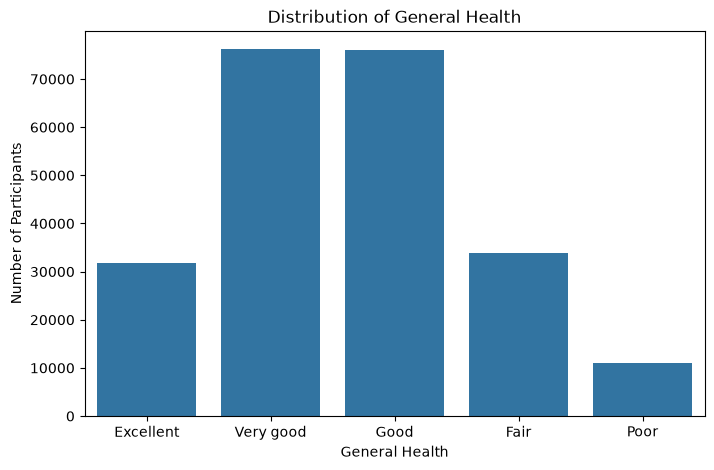

In [311]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "general_health"
)
plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Distribution of General Health")
plt.show()

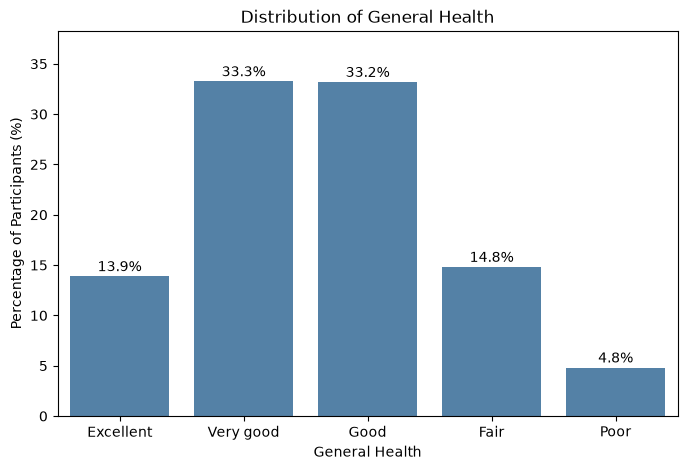

In [312]:
order = ["Excellent", "Very good", "Good", "Fair", "Poor"]

# Calculate percentages
health_pct = (
    clean_health["general_health"]
    .value_counts(normalize=True)
    .reindex(order)
    .mul(100)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=health_pct.index,
    y=health_pct.values,
    color="steelblue"
)

# Add percentage labels above bars
for i, value in enumerate(health_pct.values):
    ax.text(i, value + 0.5, f"{value:.1f}%",
            ha="center", fontsize=10)

plt.xlabel("General Health")
plt.ylabel("Percentage of Participants (%)")
plt.title("Distribution of General Health")
plt.ylim(0, health_pct.max() * 1.15)

plt.show()

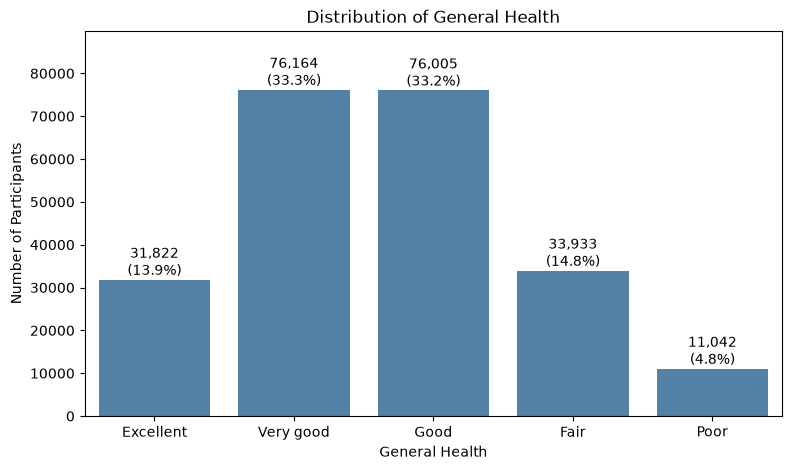

In [313]:

order = ["Excellent", "Very good", "Good", "Fair", "Poor"]

# Calculate counts and percentages
health_counts = clean_health["general_health"].value_counts().reindex(order)
health_pct = health_counts / health_counts.sum() * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=health_counts.index,
    y=health_counts.values,
    color="steelblue"
)

# Show count and percentage above each bar
for i, (count, pct) in enumerate(zip(health_counts, health_pct)):
    ax.text(
        i, count + health_counts.max() * 0.015,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        fontsize=10
    )

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Distribution of General Health")
plt.ylim(0, health_counts.max() * 1.18)

plt.show()

## Mental Health Disrtibution

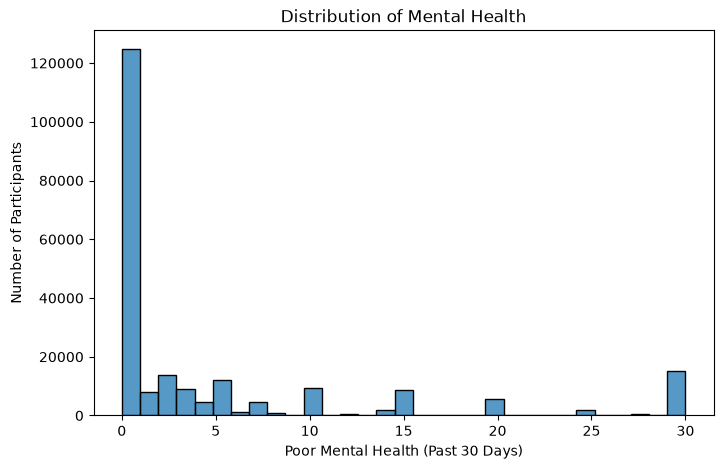

In [314]:
plt.figure(figsize = (8,5))
sns.histplot(
    data = clean_health,
    x = "MENTHLTH",
    bins=31
)
plt.xlabel("Poor Mental Health (Past 30 Days)")
plt.ylabel("Number of Participants")
plt.title("Distribution of Mental Health")
plt.show()

## Age Group Disrtibution

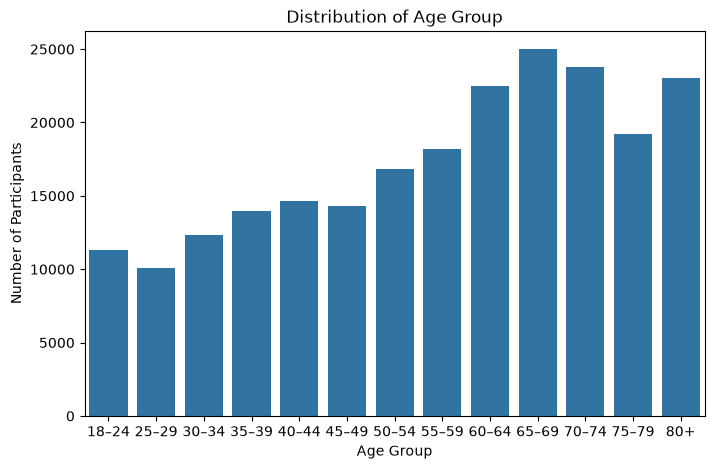

In [315]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "age_group"
)
plt.xlabel("Age Group")
plt.ylabel("Number of Participants")
plt.title("Distribution of Age Group")
plt.show()

## Race/Ethnicity Distribution

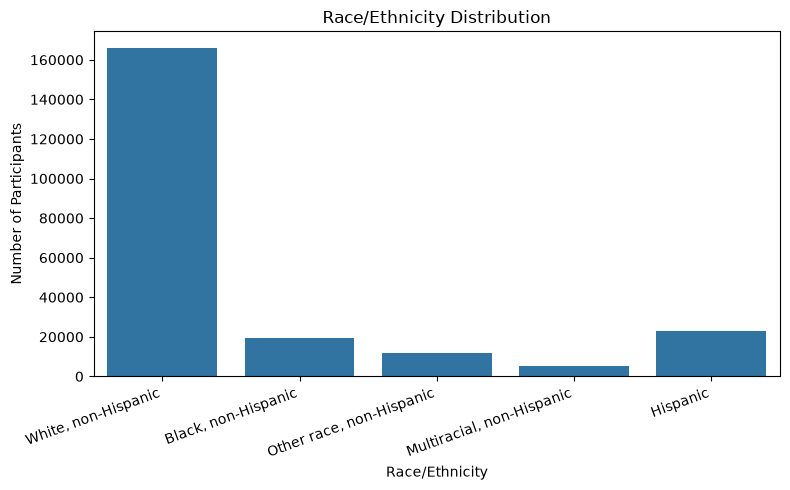

In [450]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "race_ethnicity"
)
plt.xlabel("Race/Ethnicity")
plt.ylabel("Number of Participants")
plt.title("Race/Ethnicity Distribution")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Income Distribution

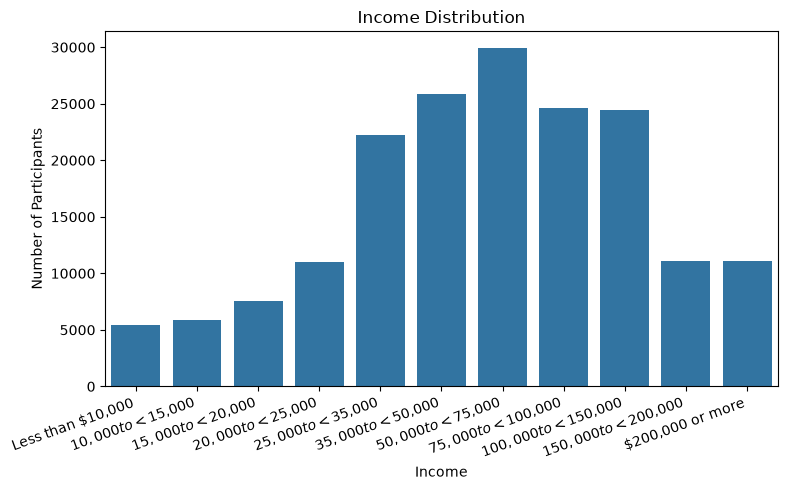

In [446]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "income"
)
plt.xlabel("Income")
plt.ylabel("Number of Participants")
plt.title("Income Distribution")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Marital Status Distribution

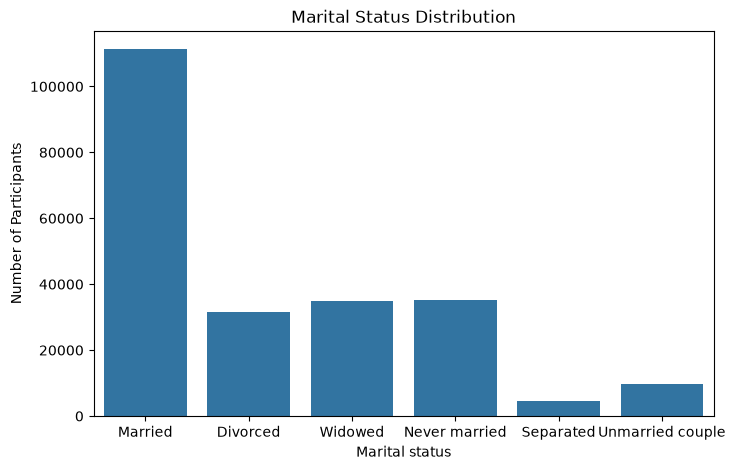

In [318]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "marital_status"
)
plt.xlabel("Marital status")
plt.ylabel("Number of Participants")
plt.title("Marital Status Distribution")
plt.show()

## Distribution of children in Household

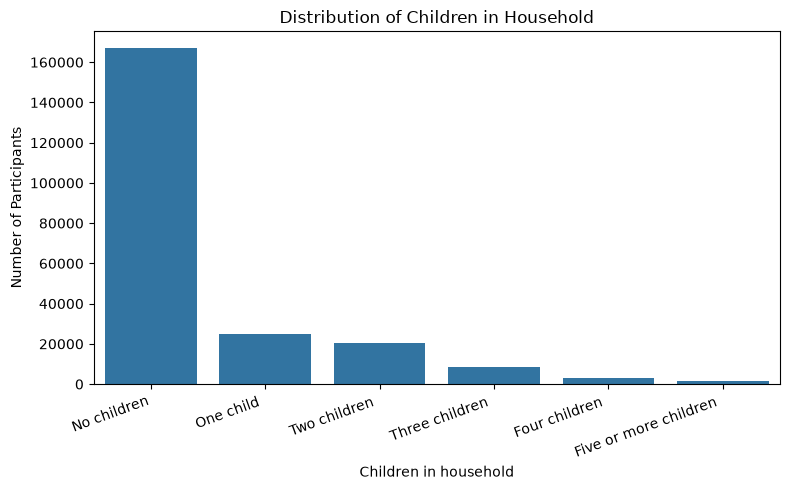

In [445]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "Children_in_household"
)
plt.xlabel("Children in household")
plt.ylabel("Number of Participants")
plt.title("Distribution of Children in Household")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Distribution of Education Level

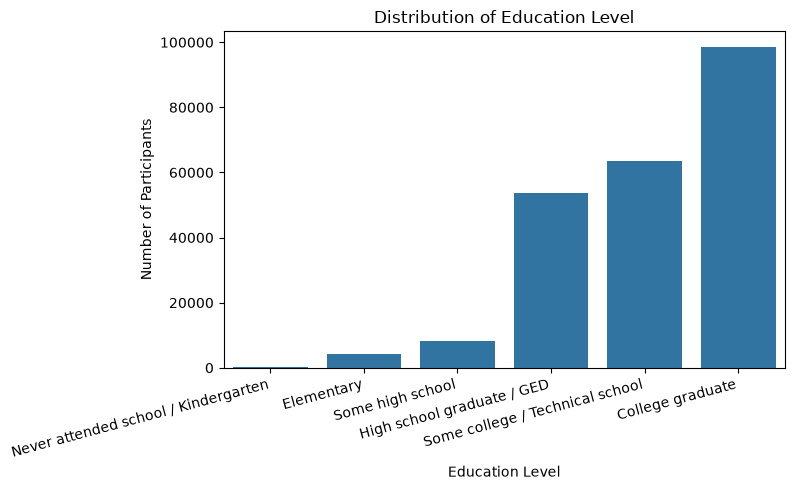

In [443]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "education"
)
plt.xlabel("Education Level")
plt.ylabel("Number of Participants")
plt.title("Distribution of Education Level")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Exercise Distribution

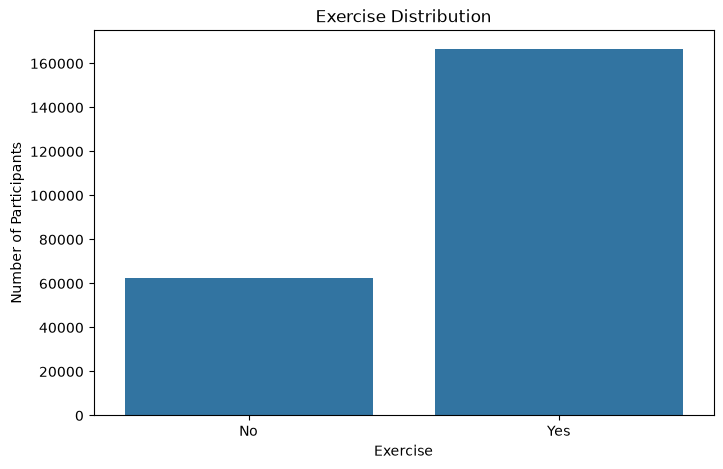

In [321]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "exercise"
)
plt.xlabel("Exercise")
plt.ylabel("Number of Participants")
plt.title("Exercise Distribution")
plt.show()

## Smoking status Distribution

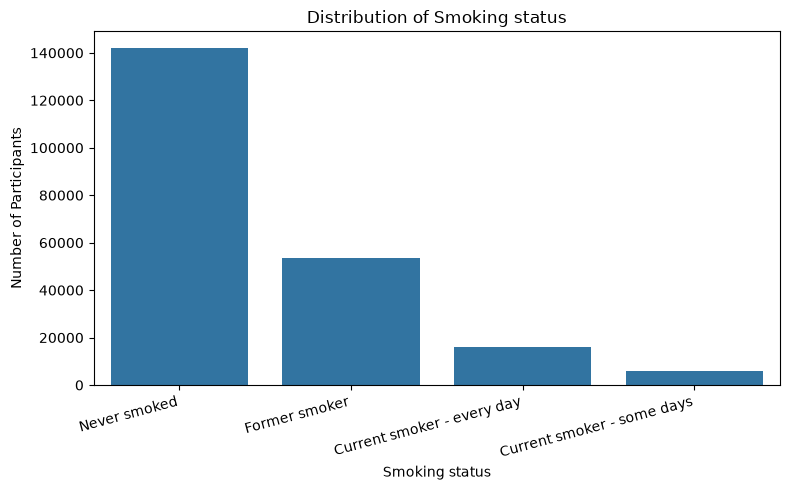

In [442]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "smoking_status"
)
plt.xlabel("Smoking status")
plt.ylabel("Number of Participants")
plt.title("Distribution of Smoking status")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## distribution weekly Alcohol consumption

#### For visualization purposes, observations above the 99th percentile of weekly alcohol consumption were excluded, and the displayed x-axis was limited to 0–21 drinks per week. This restriction was applied to the visualization and does not imply that these observations were removed from the main analytical dataset.

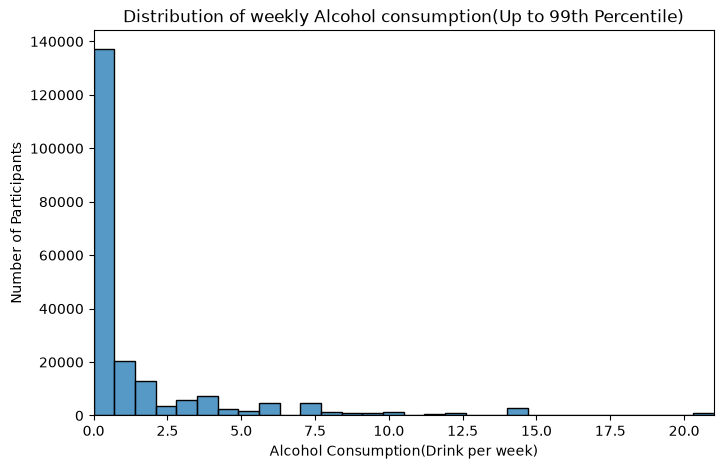

In [323]:
alcohol_99 = clean_health[
    clean_health["_DRNKWK2"] <= clean_health["_DRNKWK2"].quantile(0.99)
]

plt.figure(figsize = (8,5))
sns.histplot(
    data = alcohol_99,
    x = "_DRNKWK2",
    bins=30
)
plt.xlim(0, 21)
plt.xlabel("Alcohol Consumption(Drink per week)")
plt.ylabel("Number of Participants")
plt.title("Distribution of weekly Alcohol consumption(Up to 99th Percentile)")
plt.show()

## BMI Distribution

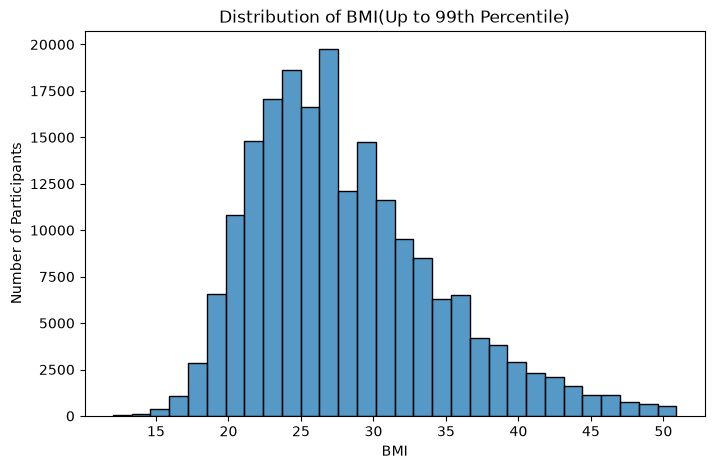

In [324]:
bmi_99 = clean_health[
    clean_health["_BMI5"] <= clean_health["_BMI5"].quantile(0.99)
]
plt.figure(figsize=(8,5))
sns.histplot(
    data = bmi_99,
    x = "_BMI5",
    bins=30
)
plt.xlabel("BMI")
plt.ylabel("Number of Participants")
plt.title("Distribution of BMI(Up to 99th Percentile)")
plt.show()

## Distribution of BMI Category

<function matplotlib.pyplot.show(close=None, block=None)>

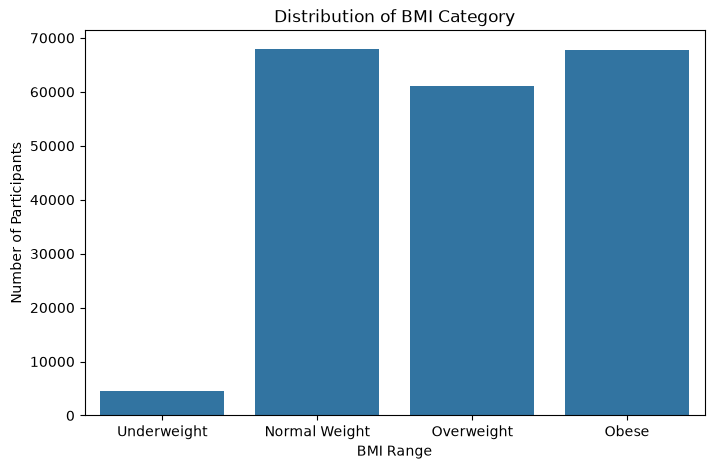

In [325]:
plt.figure(figsize = (8,5))
sns.countplot(
    data = clean_health,
    x = "BMI_range"
)
plt.xlabel("BMI Range")
plt.ylabel("Number of Participants")
plt.title("Distribution of BMI Category")
plt.show

## Stress Frequency Distribution

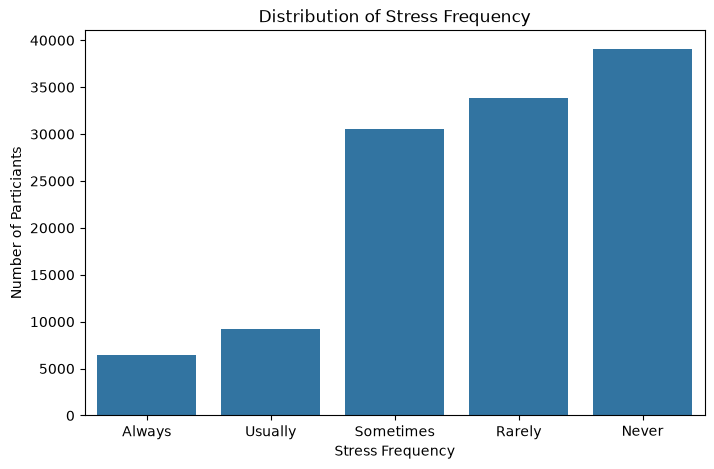

In [326]:
plt.figure(figsize = (8,5))

sns.countplot(
    data = clean_health,
    x = "stress_frequency"
)
plt.xlabel("Stress Frequency")
plt.ylabel("Number of Particiants")
plt.title("Distribution of Stress Frequency")
plt.show()

## Association between General and Mental Health

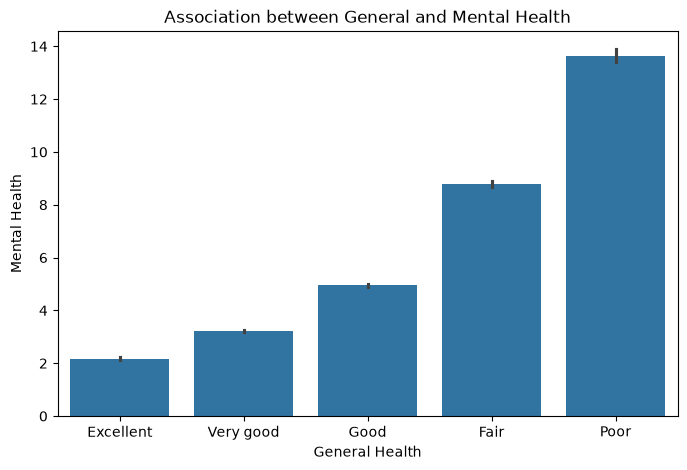

In [327]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "general_health",
    y = "MENTHLTH"
)
plt.xlabel("General Health")
plt.ylabel("Mental Health")
plt.title("Association between General and Mental Health")
plt.show()

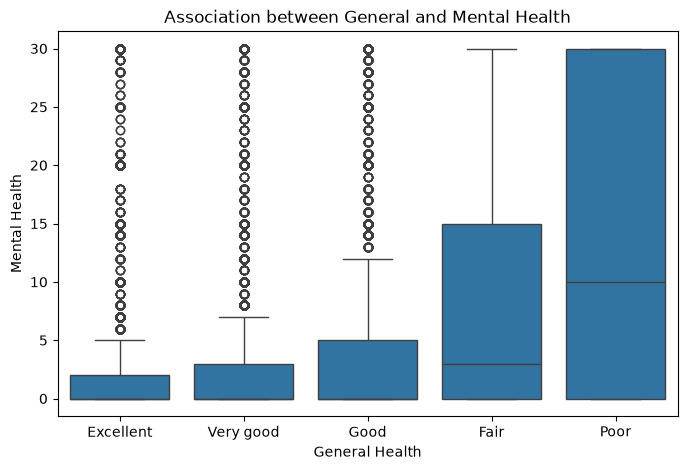

In [328]:
plt.figure(figsize = (8, 5))
sns.boxplot(
    data = clean_health,
    x = "general_health",
    y = "MENTHLTH"
)
plt.xlabel("General Health")
plt.ylabel("Mental Health")
plt.title("Association between General and Mental Health")
plt.show()

### Association between Age Group and General Health
#### Participant Counts
[original count plot]
##### General Health Distribution Within Age Groups
[100% stacked percentage plot]

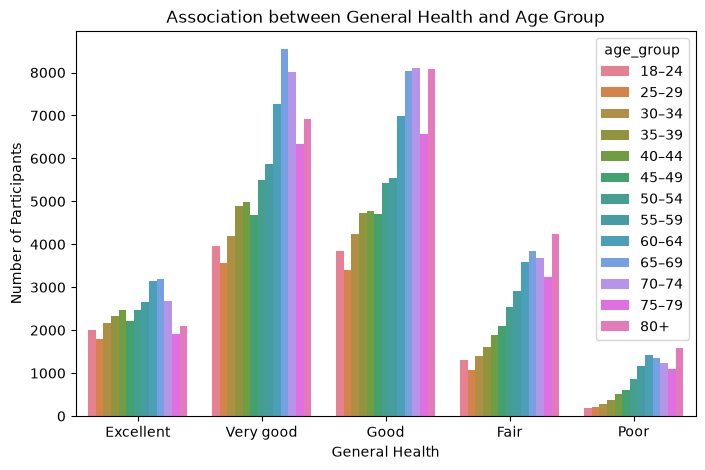

In [329]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "age_group"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Age Group")
plt.show()

In [330]:
age_health_pct = pd.crosstab(
    clean_health["age_group"],
    clean_health["general_health"],
    normalize = "index"
)* 100
age_health_pct

general_health,Excellent,Very good,Good,Fair,Poor
age_group,,,,,
18–24,17.732815,35.076869,33.990104,11.477293,1.722919
25–29,17.845419,35.442157,33.930170,10.782851,1.999403
30–34,17.701636,34.215024,34.556849,11.304631,2.221861
35–39,16.732382,35.142304,33.837551,11.563553,2.724210
40–44,16.894291,34.116362,32.682327,12.851680,3.455340
45–49,15.401833,32.748129,32.853046,14.744352,4.252640
50–54,14.745611,32.692651,32.347516,15.055043,5.159179
55–59,14.665197,32.383577,30.548360,16.009920,6.392946
60–64,14.060271,32.413516,31.200963,15.963802,6.361448


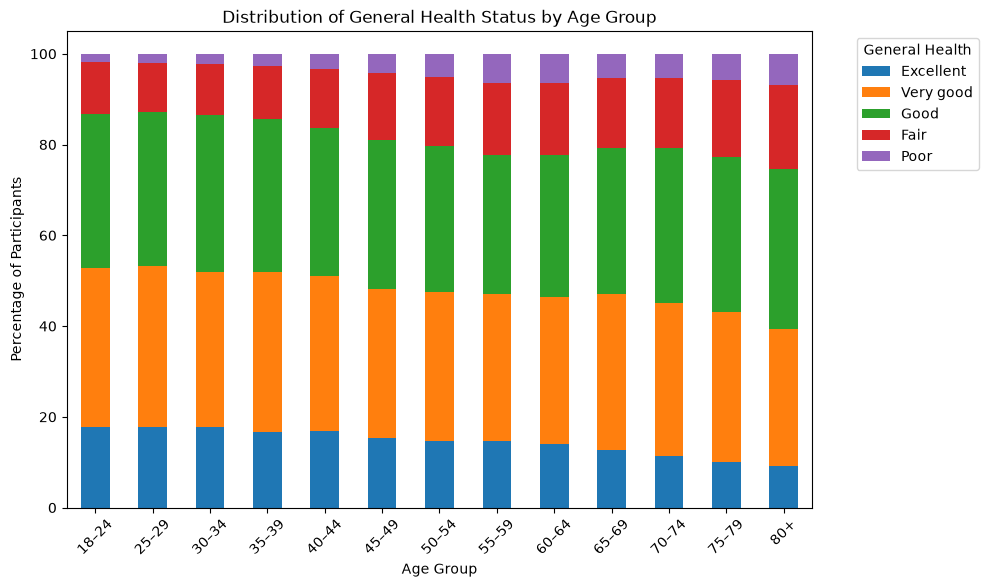

In [331]:
age_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Age Group")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Age Group")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Race and General Health
#### Participant Counts
[original count plot]
##### General Health Distribution Within Race/Ethnicity
[100% stacked percentage plot]

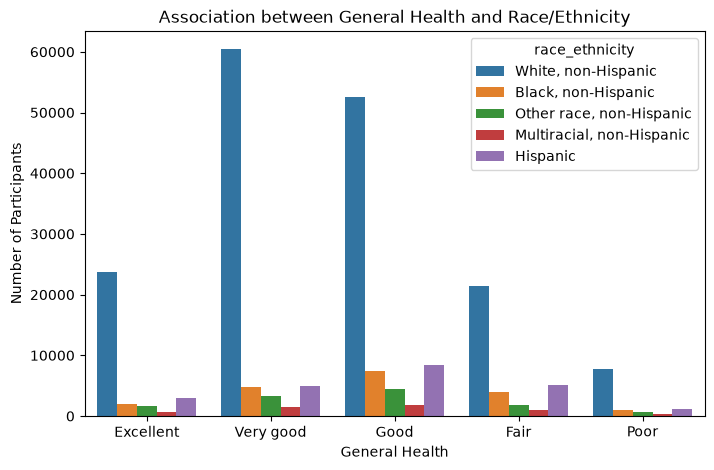

In [332]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "race_ethnicity"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Race/Ethnicity")
plt.show()

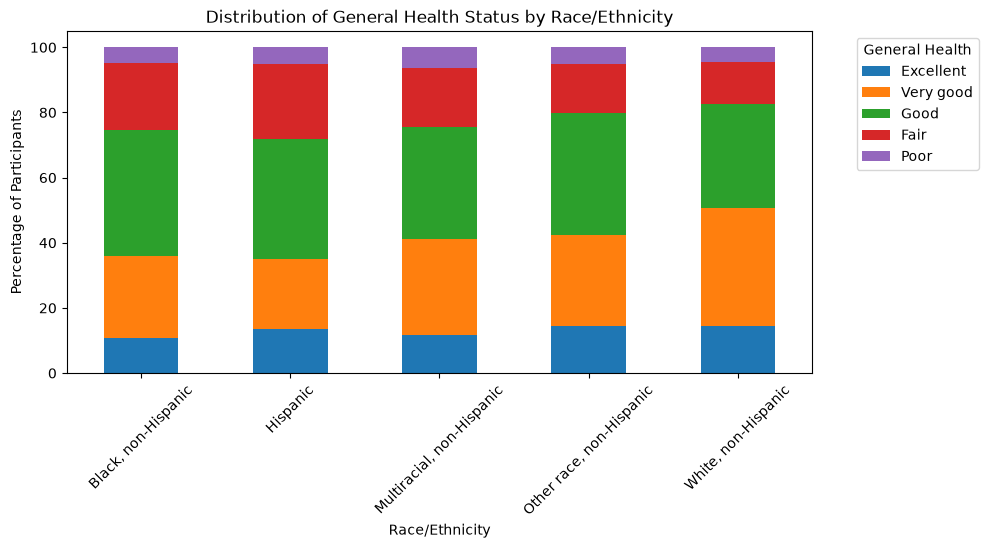

In [333]:
race_health_pct = pd.crosstab(
    clean_health["race_ethnicity"],
    clean_health["general_health"],
    normalize = "index"
)* 100

race_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Race/Ethnicity")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Race/Ethnicity")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Income and General Health
#### Participant Counts
[original count plot]
##### General Health Distribution Within Income
[100% stacked percentage plot]

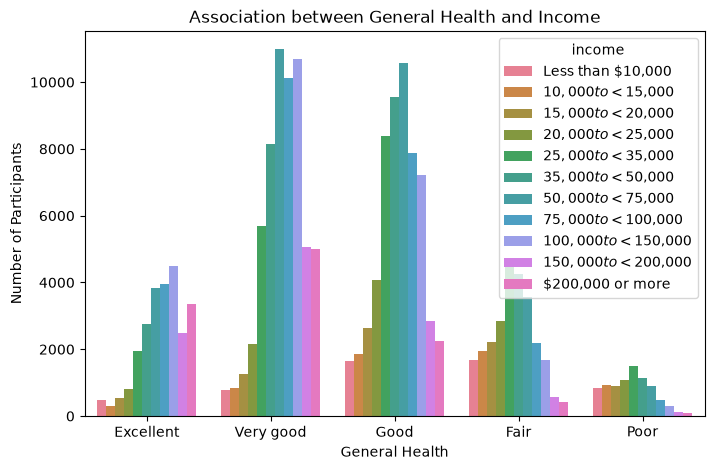

In [334]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "income"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Income")
plt.show()

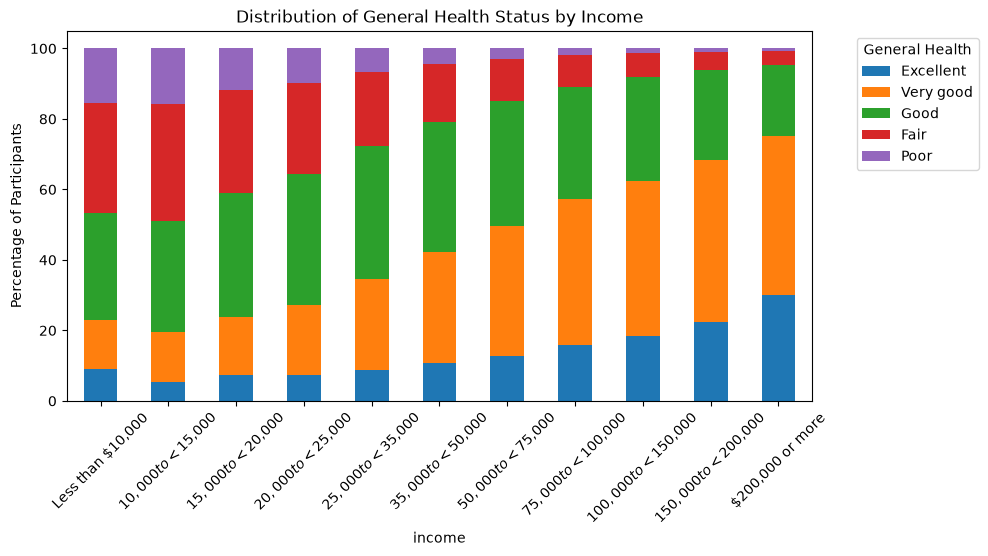

In [335]:
income_health_pct = pd.crosstab(
    clean_health["income"],
    clean_health["general_health"],
    normalize = "index"
)* 100

income_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("income")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Income")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Marital status and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within Marital Status
[100% stacked percentage plot]

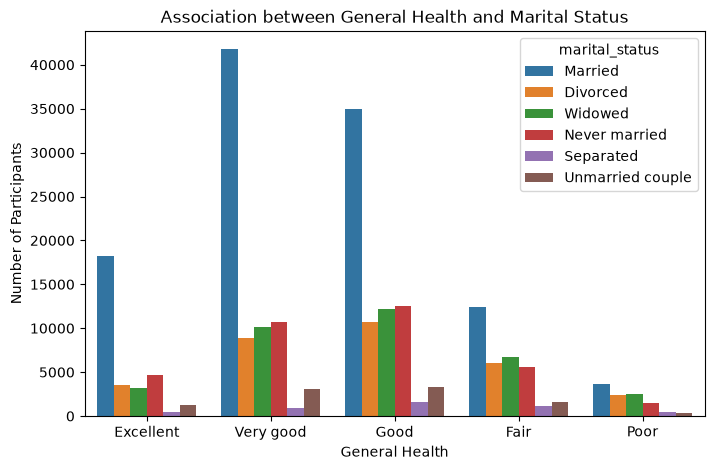

In [336]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "marital_status"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Marital Status")
plt.show()

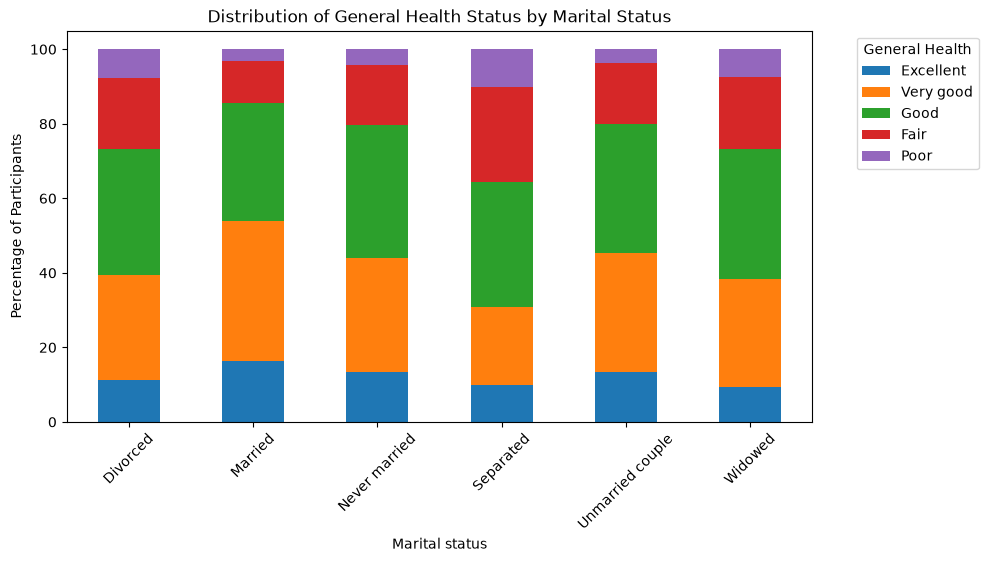

In [337]:
marital_health_pct = pd.crosstab(
    clean_health["marital_status"],
    clean_health["general_health"],
    normalize = "index"
)* 100

marital_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Marital status")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Marital Status")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Children in household and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within Children in Household
[100% stacked percentage plot]

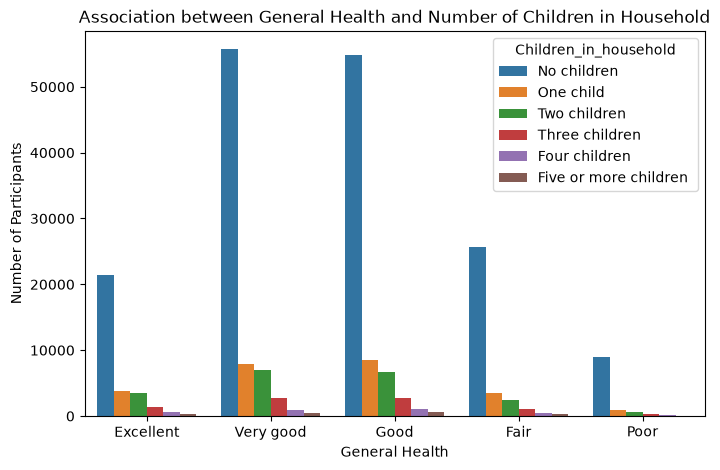

In [338]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "Children_in_household"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Number of Children in Household")
plt.show()

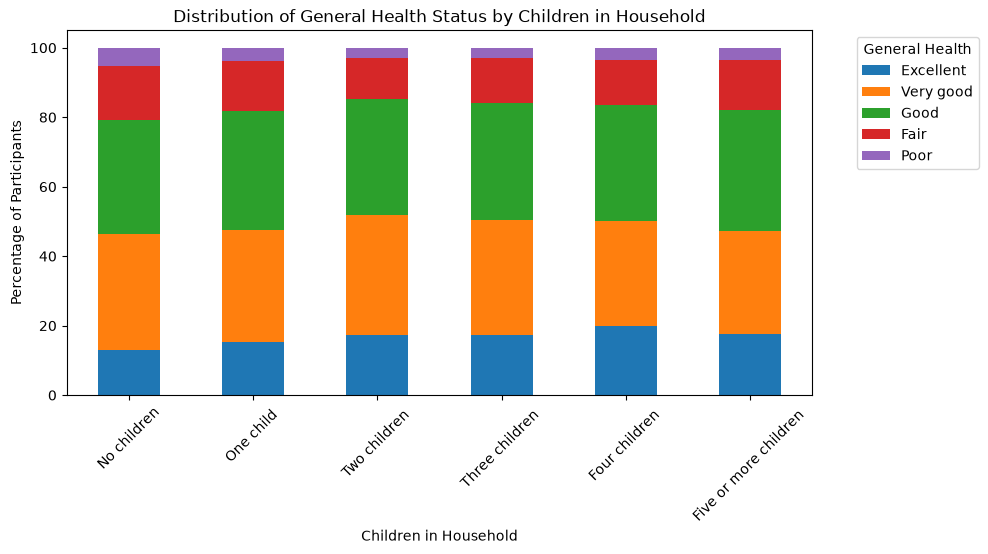

In [339]:
children_health_pct = pd.crosstab(
    clean_health["Children_in_household"],
    clean_health["general_health"],
    normalize = "index"
)* 100

children_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Children in Household")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Children in Household")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Education level and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within Education
[100% stacked percentage plot]

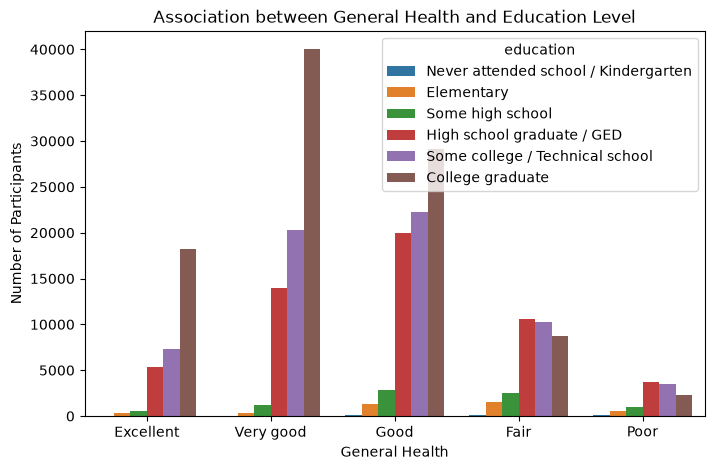

In [340]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "education"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Education Level")
plt.show()

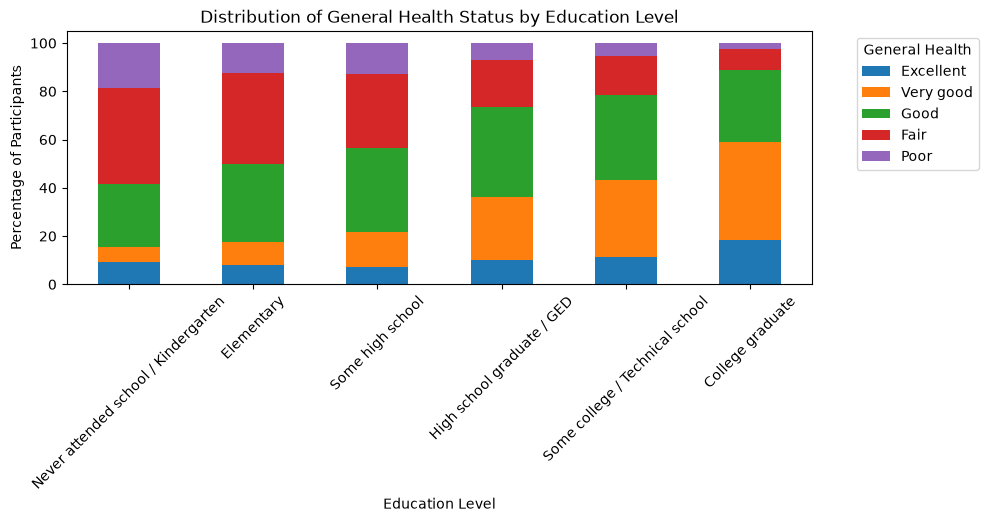

In [441]:
education_health_pct = pd.crosstab(
    clean_health["education"],
    clean_health["general_health"],
    normalize = "index"
)* 100

education_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Education Level")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Education Level")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Exercise and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within Exercise
[100% stacked percentage plot]

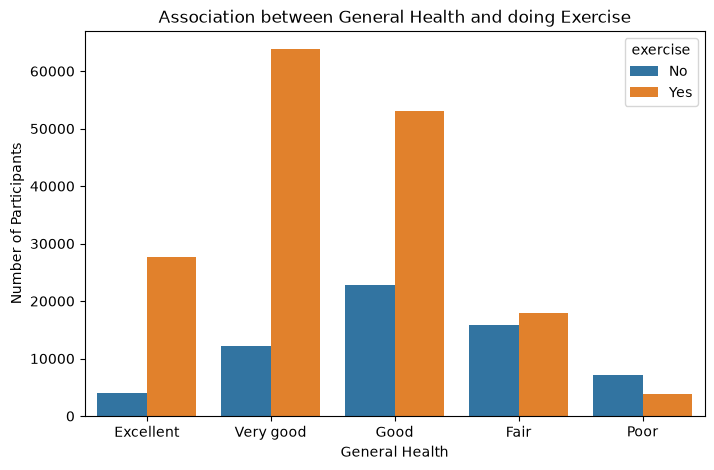

In [342]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "exercise"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and doing Exercise")
plt.show()

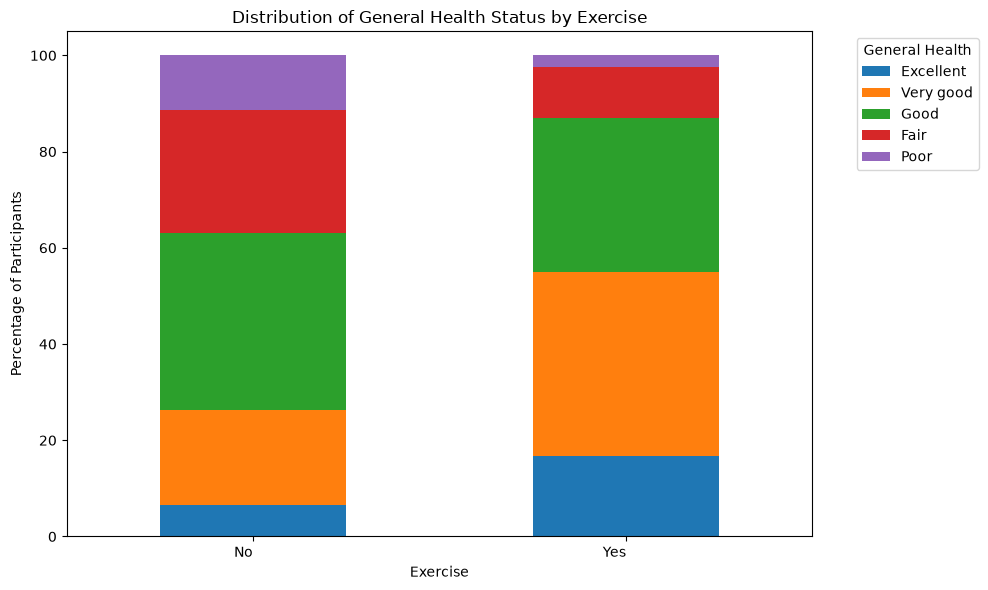

In [439]:
exercise_health_pct = pd.crosstab(
    clean_health["exercise"],
    clean_health["general_health"],
    normalize = "index"
)* 100

exercise_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Exercise")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Exercise")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.xticks(rotation=360, ha="right")
plt.tight_layout()
plt.show()

### Association between Smoking and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within Smoking Status
[100% stacked percentage plot]

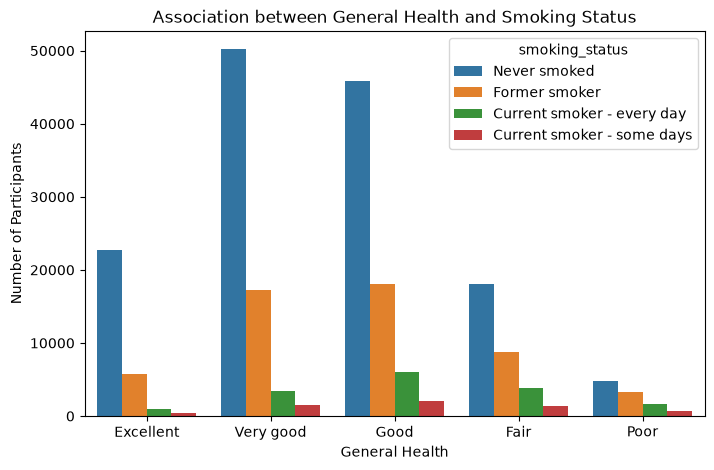

In [344]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "smoking_status"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Smoking Status")
plt.show()

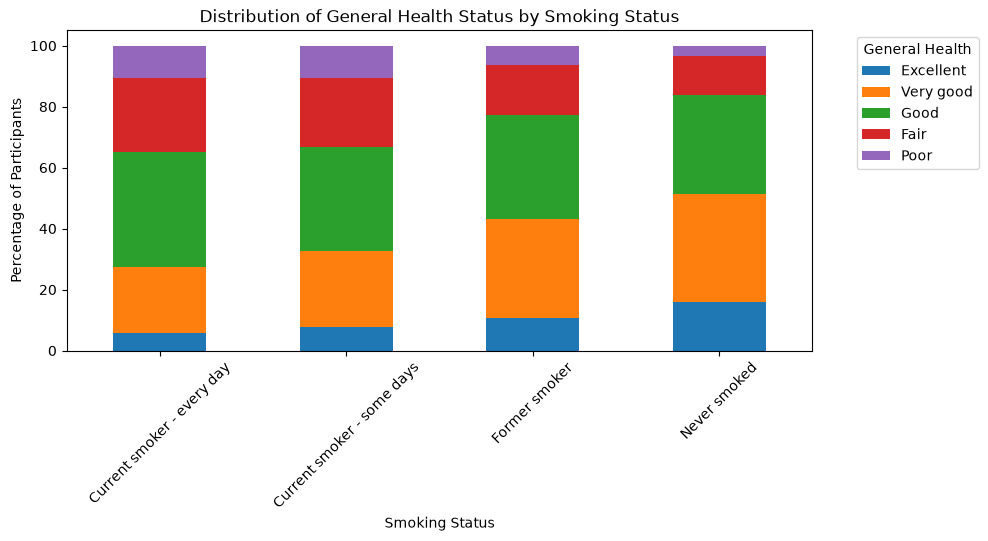

In [345]:
smoking_health_pct = pd.crosstab(
    clean_health["smoking_status"],
    clean_health["general_health"],
    normalize = "index"
)* 100

smoking_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Smoking Status")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Smoking Status")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Alcoho consumption and General Health

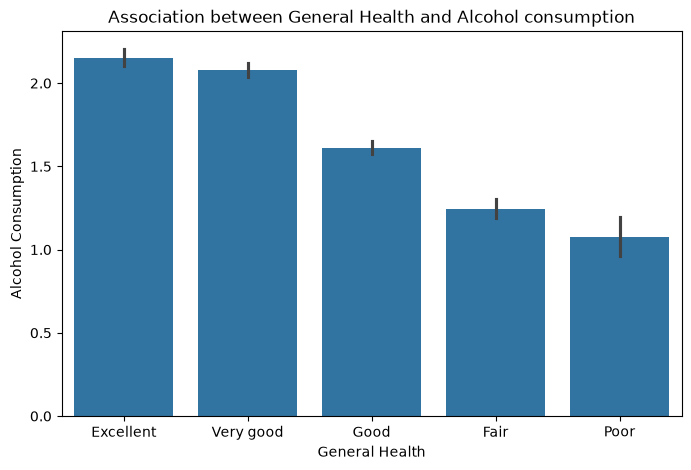

In [346]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "general_health",
    y = "_DRNKWK2"
)

plt.xlabel("General Health")
plt.ylabel("Alcohol Consumption")
plt.title("Association between General Health and Alcohol consumption")
plt.show()

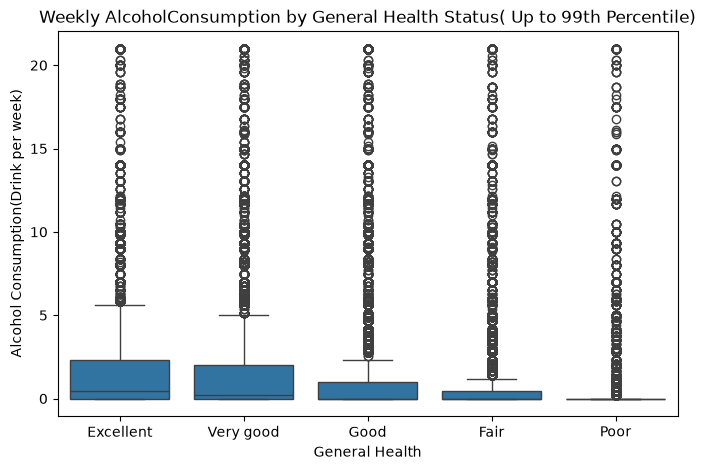

In [347]:
alcohol_99 = clean_health[
    clean_health["_DRNKWK2"] <= clean_health["_DRNKWK2"].quantile(0.99)
]
plt.figure(figsize = (8, 5))
sns.boxplot(
    data = alcohol_99,
    x = "general_health",
    y = "_DRNKWK2"
)

plt.xlabel("General Health")
plt.ylabel("Alcohol Consumption(Drink per week)")
plt.title("Weekly AlcoholConsumption by General Health Status( Up to 99th Percentile)")
plt.show()

### Association between BMI and General Health

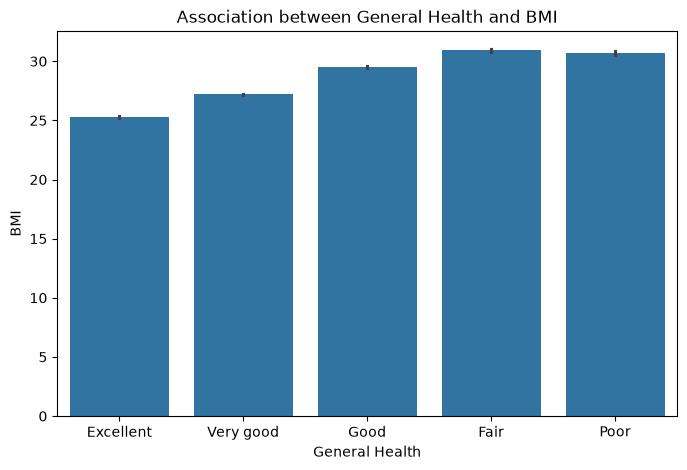

In [348]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "general_health",
    y = "_BMI5"
)

plt.xlabel("General Health")
plt.ylabel("BMI")
plt.title("Association between General Health and BMI")
plt.show()

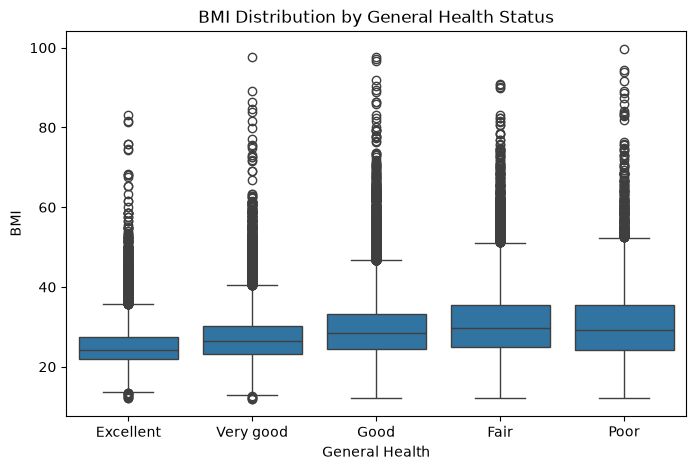

In [349]:
plt.figure(figsize = (8, 5))
sns.boxplot(
    data = clean_health,
    x = "general_health",
    y = "_BMI5"
)

plt.xlabel("General Health")
plt.ylabel("BMI")
plt.title("BMI Distribution by General Health Status")
plt.show()

### Association between BMI Category and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within BMI range
[100% stacked percentage plot]

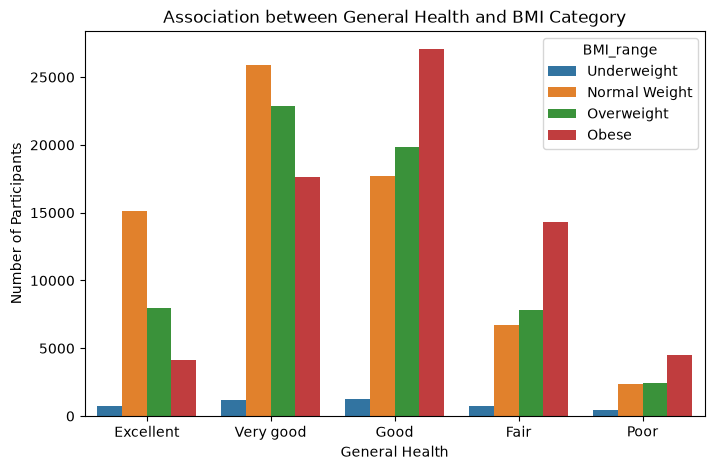

In [350]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "BMI_range"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and BMI Category")
plt.show()

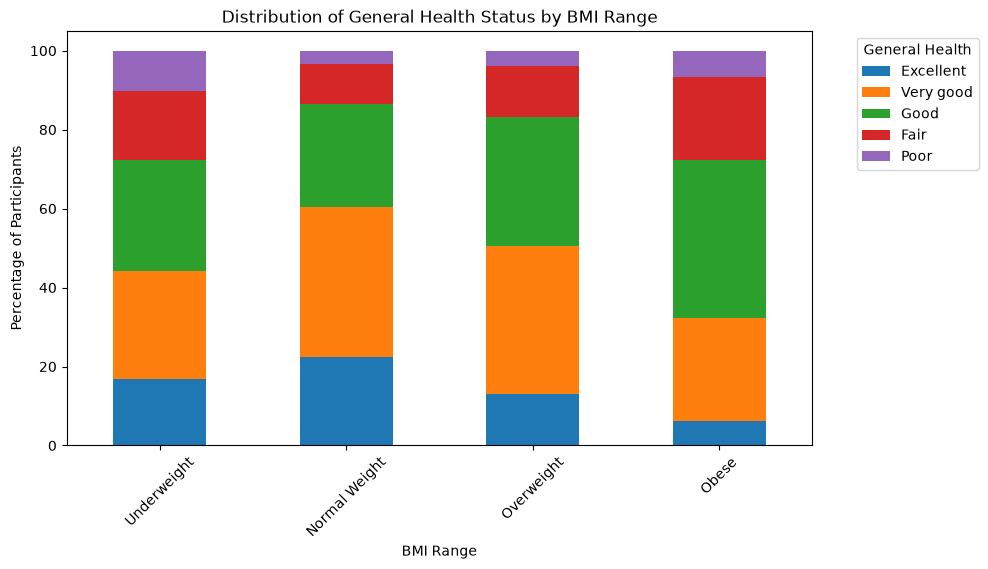

In [351]:
BMI_health_pct = pd.crosstab(
    clean_health["BMI_range"],
    clean_health["general_health"],
    normalize = "index"
)* 100

BMI_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("BMI Range")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by BMI Range")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

### Association between Stress frequency and General Health
#### Participant Counts
[original count plot]

#### General Health Distribution Within  Stress Frequency
[100% stacked percentage plot]

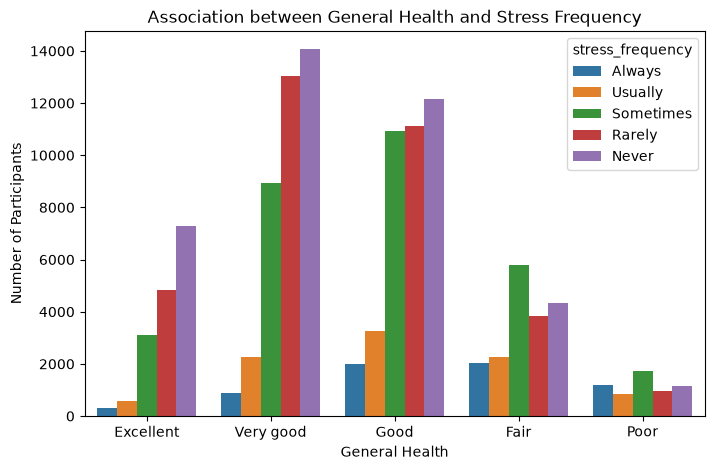

In [352]:
plt.figure(figsize = (8, 5))
sns.countplot(
    data = clean_health,
    x = "general_health",
    hue = "stress_frequency"
)

plt.xlabel("General Health")
plt.ylabel("Number of Participants")
plt.title("Association between General Health and Stress Frequency")
plt.show()

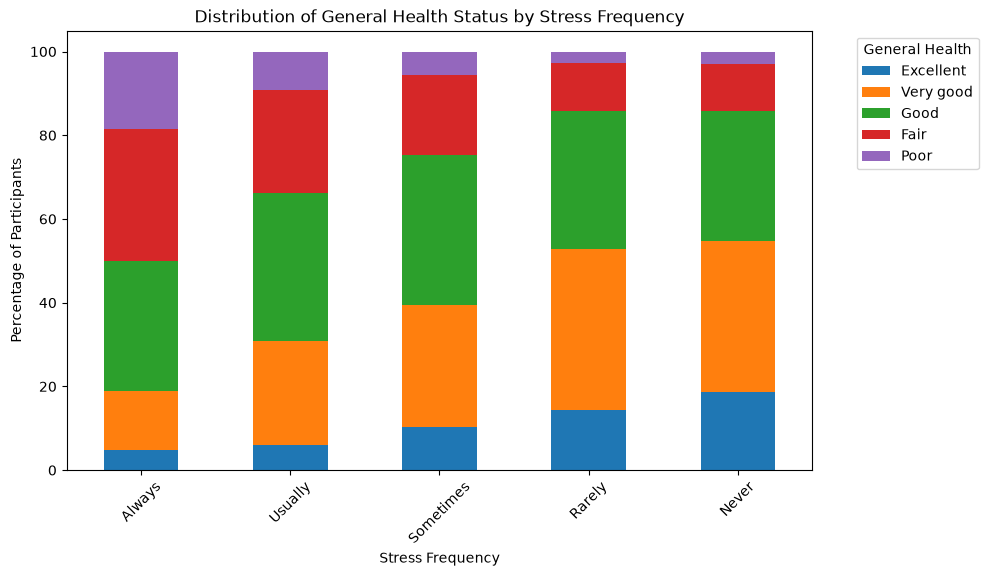

In [353]:
stress_health_pct = pd.crosstab(
    clean_health["stress_frequency"],
    clean_health["general_health"],
    normalize = "index"
)* 100

stress_health_pct.plot(
    kind = "bar",
    stacked = True,
    figsize = (10, 6)
)

plt.xlabel("Stress Frequency")
plt.ylabel("Percentage of Participants")
plt.title("Distribution of General Health Status by Stress Frequency")
plt.legend(
    title = "General Health",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)
plt.tight_layout()
plt.xticks(rotation = 45)
plt.show()

## Association between Age and Mental Health

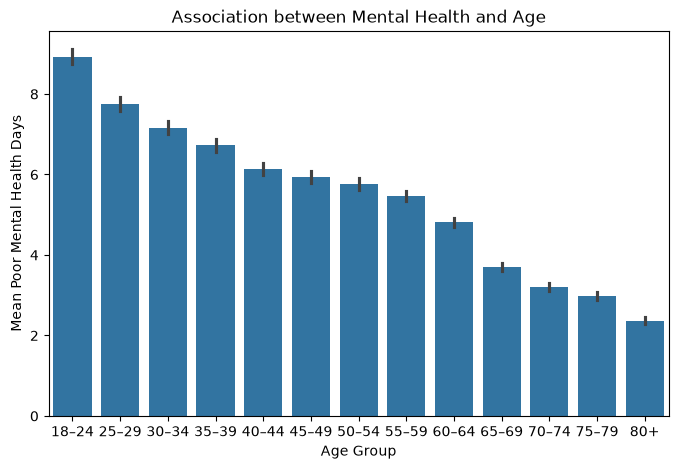

In [354]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "age_group",
    y = "MENTHLTH"
)

plt.xlabel("Age Group")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Age")
plt.show()

## Association between Race and Mental Health

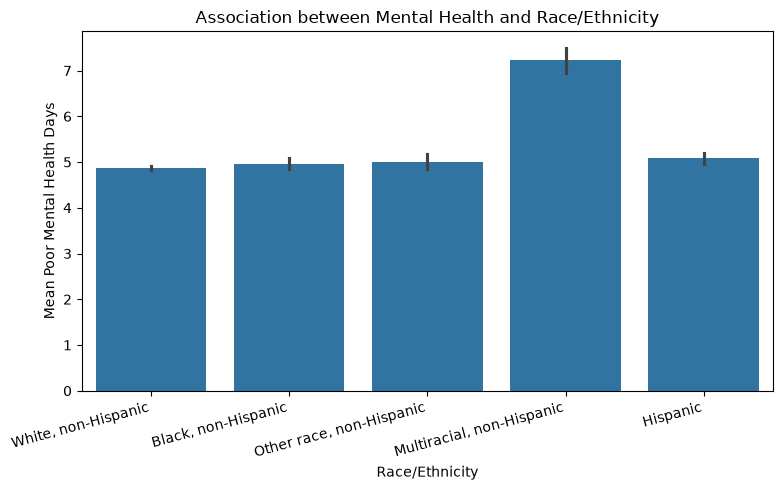

In [435]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "race_ethnicity",
    y = "MENTHLTH"
)

plt.xlabel("Race/Ethnicity")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Race/Ethnicity")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Association between Income and Mental Health

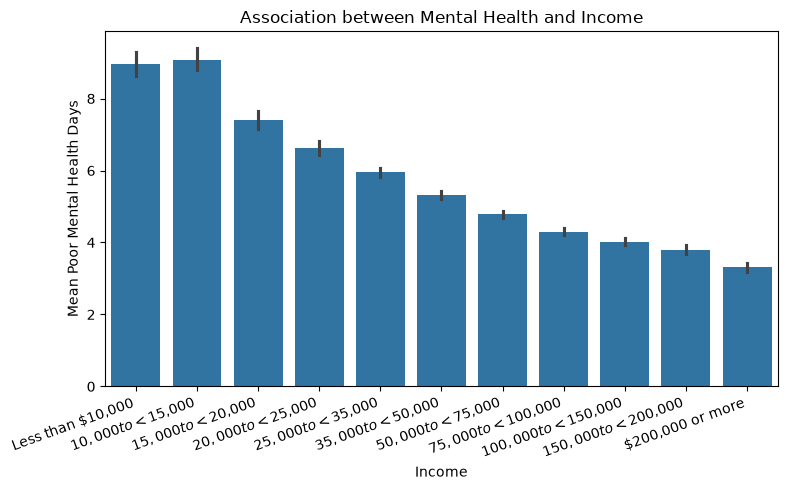

In [434]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "income",
    y = "MENTHLTH"
)

plt.xlabel("Income")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Income")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Association between Marital status and Mental Health

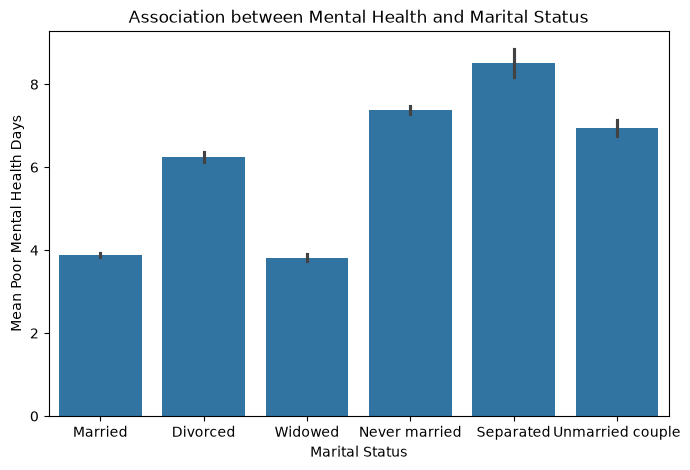

In [357]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "marital_status",
    y = "MENTHLTH"
)

plt.xlabel("Marital Status")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Marital Status")
plt.show()

## Association between Children in household and Mental Health

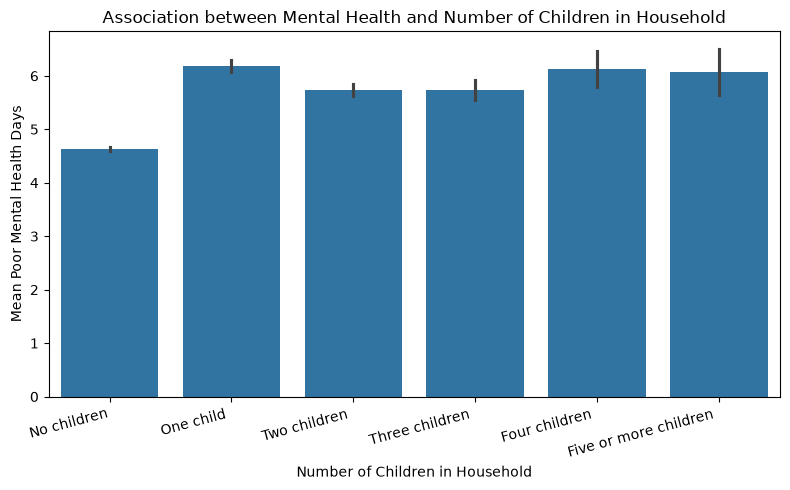

In [432]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "Children_in_household",
    y = "MENTHLTH"
)

plt.xlabel("Number of Children in Household")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Number of Children in Household")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Association between Education level and Mental Health

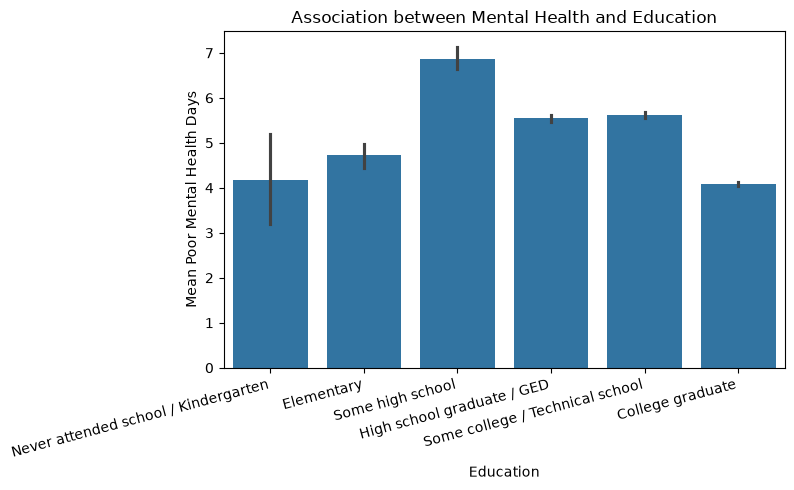

In [431]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "education",
    y = "MENTHLTH"
)

plt.xlabel("Education")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Education")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Association between Exercise and Mental Health

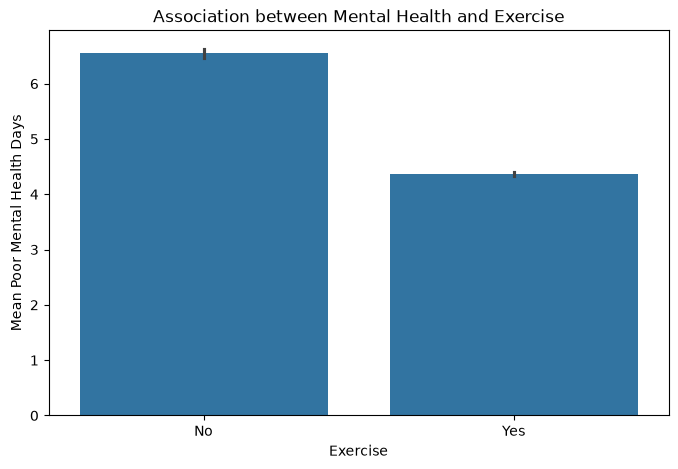

In [360]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "exercise",
    y = "MENTHLTH"
)

plt.xlabel("Exercise")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Exercise")
plt.show()

## Association between Smoking and Mental Health

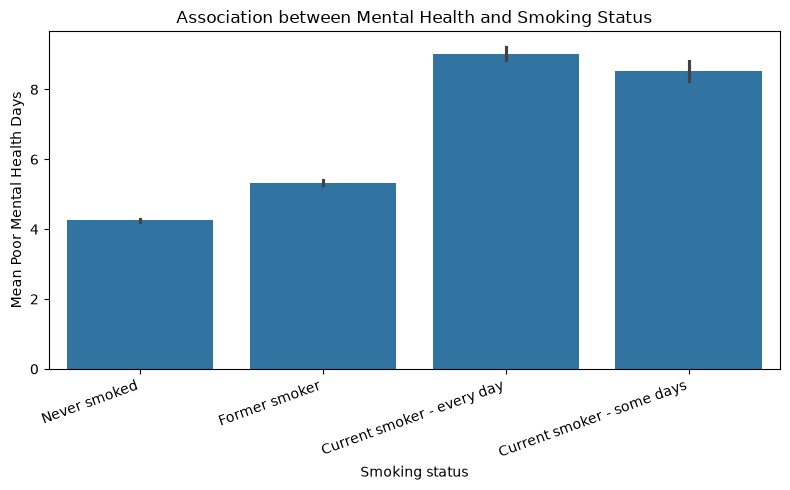

In [427]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "smoking_status",
    y = "MENTHLTH"
)

plt.xlabel("Smoking status")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and Smoking Status")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Association between Alcohol consumption and Mental Health

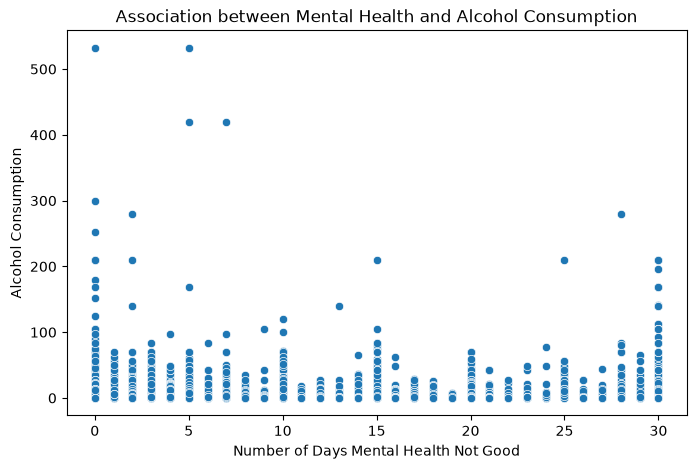

In [362]:
plt.figure(figsize = (8, 5))
sns.scatterplot(
    data = clean_health,
    x = "MENTHLTH",
    y = "_DRNKWK2"
)

plt.xlabel("Number of Days Mental Health Not Good")
plt.ylabel("Alcohol Consumption")
plt.title("Association between Mental Health and Alcohol Consumption")
plt.show()

## Association between BMI and Mental Health

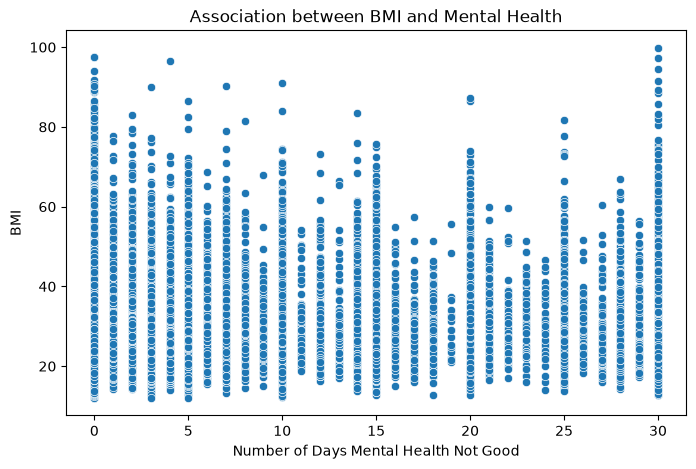

In [363]:
plt.figure(figsize = (8, 5))
sns.scatterplot(
    data = clean_health,
    x = "MENTHLTH",
    y = "_BMI5"
)

plt.xlabel("Number of Days Mental Health Not Good")
plt.ylabel("BMI")
plt.title("Association between BMI and Mental Health")
plt.show()

## Association between BMI Category and Mental Health

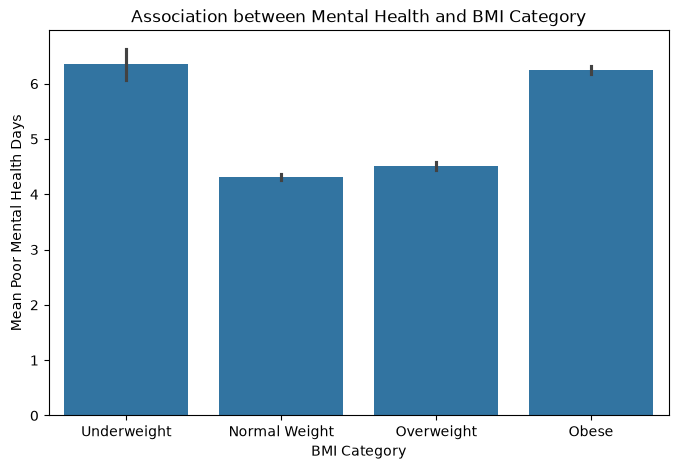

In [364]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "BMI_range",
    y = "MENTHLTH"
)

plt.xlabel("BMI Category")
plt.ylabel("Mean Poor Mental Health Days")
plt.title("Association between Mental Health and BMI Category")
plt.show()

## Association between Stress Frecuency and Mental Health

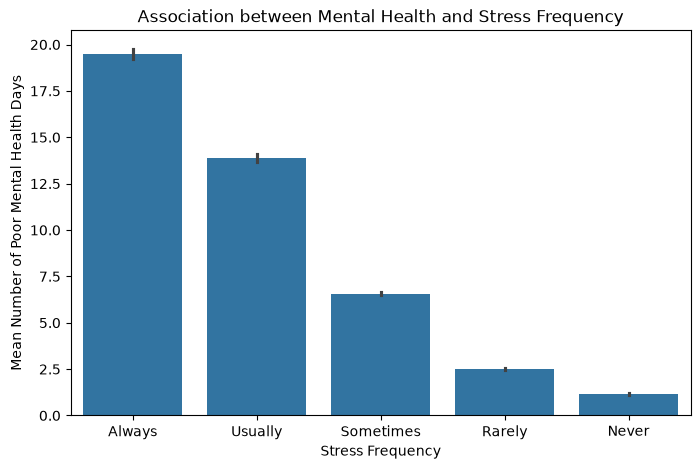

In [365]:
plt.figure(figsize = (8, 5))
sns.barplot(
    data = clean_health,
    x = "stress_frequency",
    y = "MENTHLTH"
)

plt.xlabel("Stress Frequency")
plt.ylabel("Mean Number of Poor Mental Health Days")
plt.title("Association between Mental Health and Stress Frequency")
plt.show()

In [366]:
correlation_data = clean_health[["MENTHLTH","general_health"]].dropna()
print(correlation_data)

        MENTHLTH general_health
0            0.0      Very good
1            0.0      Very good
2            2.0           Fair
3            0.0      Very good
4            0.0           Fair
...          ...            ...
229518       2.0           Good
229519       0.0           Good
229520       0.0      Very good
229521       0.0      Very good
229522       0.0           Good

[224683 rows x 2 columns]


In [367]:
print(clean_health["general_health"].dtype)
print(clean_health["general_health"].unique())

category
['Very good', 'Fair', 'Good', 'Poor', 'Excellent', NaN]
Categories (5, str): ['Excellent' < 'Very good' < 'Good' < 'Fair' < 'Poor']


In [368]:
correlation_data["general_health_rank"] = (
    correlation_data["general_health"].cat.codes + 1
)

In [369]:
from scipy import stats

In [370]:
r, p_value = stats.spearmanr(
    correlation_data["MENTHLTH"],
    correlation_data["general_health_rank"]
)
print("Spearman r: ", r)
print("P-value: ", p_value)

Spearman r:  0.2490409863595878
P-value:  0.0


##### There was a statistically significant weak positive association between poorer general health and a greater number of poor mental-health days.
##### Spearman's ρ = 0.249, p < 0.001

In [371]:
age_data = clean_health[["age_group", "general_health"]].dropna()

In [372]:
print(age_data["age_group"].dtype)
print(age_data["age_group"].cat.categories)

category
Index(['18–24', '25–29', '30–34', '35–39', '40–44', '45–49', '50–54', '55–59',
       '60–64', '65–69', '70–74', '75–79', '80+'],
      dtype='str')


In [373]:
age_data["age_rank"] = age_data["age_group"].cat.codes + 1
age_data["general_health_rank"] = age_data["general_health"].cat.codes + 1

In [374]:
r, p_value = stats.spearmanr(
    age_data["age_rank"],
    age_data["general_health_rank"]
)
print("Spearman r: ", r)
print("P-value: ", p_value)

Spearman r:  0.10285326724930911
P-value:  0.0


##### There is a statistically significant, weak positive association between age and poorer general health
##### Spearman's ρ = 0.103 , p < 0.001

In [375]:
race_health_table = pd.crosstab(
    clean_health["race_ethnicity"],
    clean_health["general_health"]
)
race_health_table

general_health,Excellent,Very good,Good,Fair,Poor
race_ethnicity,,,,,
"Black, non-Hispanic",2056,4856,7474,3943,940
Hispanic,3037,4882,8396,5168,1183
"Multiracial, non-Hispanic",599,1512,1774,922,329
"Other race, non-Hispanic",1721,3284,4450,1782,607
"White, non-Hispanic",23802,60401,52481,21398,7674


In [376]:
chi2, p_value, dof, expected = stats.chi2_contingency(race_health_table) 

In [377]:
print("Chi-square:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())

Chi-square: 4492.9646037423045
P-value: 0.0
Degrees of freedom: 16
Minimum expected frequency: 245.35738034726333


In [378]:
n = race_health_table.to_numpy().sum()
k = min(race_health_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * k))

print("Cramér's V:", cramers_v)

Cramér's V: 0.07070709485756221


#### A Chi-square test identified a statistically significant association between race/ethnicity and general health, χ²(16) = 4492.96, p < 0.001. However, Cramér's V (0.071) indicated a very weak association.

In [379]:
print(clean_health["education"].cat.categories)

Index(['Never attended school / Kindergarten', 'Elementary',
       'Some high school', 'High school graduate / GED',
       'Some college / Technical school', 'College graduate'],
      dtype='str')


In [380]:
education_data = clean_health[
    ["education", "general_health"]
].dropna().copy()

education_data["education_rank"] = education_data["education"].cat.codes + 1
education_data["general_health_rank"] = education_data["general_health"].cat.codes + 1

r, p_value = stats.spearmanr(
    education_data["education_rank"],
    education_data["general_health_rank"]
)

print("Spearman r: ", r)
print("P-value: ", p_value)


Spearman r:  -0.2539306761030129
P-value:  0.0


#### A statistically significant, weak negative correlation was found between education level and poorer general health (Spearman's ρ = −0.254, p < 0.001). Higher educational attainment was associated with better self-reported general health.

In [381]:
print(clean_health["income"].cat.categories)

Index(['Less than $10,000', '$10,000 to < $15,000', '$15,000 to < $20,000',
       '$20,000 to < $25,000', '$25,000 to < $35,000', '$35,000 to < $50,000',
       '$50,000 to < $75,000', '$75,000 to < $100,000',
       '$100,000 to < $150,000', '$150,000 to < $200,000', '$200,000 or more'],
      dtype='str')


In [382]:
income_data = clean_health[
    ["income", "general_health"]
].dropna().copy()

income_data["income_rank"] = income_data["income"].cat.codes + 1
income_data["general_health_rank"] = income_data["general_health"].cat.codes + 1

r, p_value = stats.spearmanr(
    income_data["income_rank"],
    income_data["general_health_rank"]
)

print("Spearman r: ", r)
print("P-value: ", p_value)

Spearman r:  -0.34617457364805004
P-value:  0.0


#### A statistically significant, moderate negative association was found between income level and poorer general health (Spearman's ρ = −0.346, p < 0.001). Higher income was associated with better self-reported general health.

In [383]:
marital_health_table = pd.crosstab(
    clean_health["marital_status"],
    clean_health["general_health"]
)

marital_health_table

general_health,Excellent,Very good,Good,Fair,Poor
marital_status,,,,,
Divorced,3524,8917,10704,6013,2452
Married,18260,41753,35002,12448,3594
Never married,4675,10763,12558,5619,1493
Separated,463,967,1559,1183,465
Unmarried couple,1293,3044,3328,1570,359
Widowed,3238,10096,12139,6762,2562


In [384]:
chi2, p_value, dof, expected = stats.chi2_contingency(marital_health_table)

print("chi-square: ", chi2)
print("P-value: ", p_value)
print("Degrees of freedom: ", dof)
print("Minimum expected frequency:", expected.min())

chi-square:  7015.848488825213
P-value:  0.0
Degrees of freedom:  20
Minimum expected frequency: 223.36223506743738


In [385]:
n = marital_health_table.to_numpy().sum()
k = min(marital_health_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * k))

print("Cramér's V: ", cramers_v)

Cramér's V:  0.08793984741557427


#### A Chi-square test showed a statistically significant association between marital status and general health (χ²(20) = 7015.85, p < 0.001). However, Cramér's V (0.088) indicated a very weak association.

In [386]:
print(clean_health["Children_in_household"].cat.categories)

Index(['No children', 'One child ', 'Two children ', 'Three children ',
       'Four children ', 'Five or more children '],
      dtype='str')


In [387]:
children_data = clean_health[
    ["Children_in_household", "general_health"]
].dropna().copy()

children_data["children_rank"] = children_data["Children_in_household"].cat.codes + 1
children_data["general_health_rank"] = children_data["general_health"].cat.codes + 1

r, p_value = stats.spearmanr(
    children_data["children_rank"],
    children_data["general_health_rank"]
)

print("Spearman r: ", r)
print("P-value: ", p_value)

Spearman r:  -0.05236605006415705
P-value:  3.3658640613290123e-136


#### A statistically significant but very weak negative correlation was found between the number of children in the household and poorer general health (Spearman's ρ = −0.052, p < 0.001). Women living with more children tended to report slightly better general health.

In [388]:
exercise_health_table = pd.crosstab(
    clean_health["exercise"],
    clean_health["general_health"]
)

chi2, p_value, dof, expected = stats.chi2_contingency(exercise_health_table)

n = exercise_health_table.to_numpy().sum()
k = min(exercise_health_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * k))

print("Chi-square: ", chi2)
print("P-value: ", p_value)
print("Degrees od freedom: ", dof)
print("Minimum expected frequency: ", expected.min())
print("Cramér's V: ", cramers_v)


Chi-square:  22799.190515816234
P-value:  0.0
Degrees od freedom:  4
Minimum expected frequency:  2981.3151699858126
Cramér's V:  0.31596449688322126


#### A Chi-square test identified a statistically significant association between exercise participation and general health (χ²(4) = 22,799.19, p < 0.001). Cramér's V (0.316) indicated a moderate association.

In [389]:
smoking_health_table = pd.crosstab(
    clean_health["smoking_status"],
    clean_health["general_health"]
)

chi2, p_value, dof, expected = stats.chi2_contingency(smoking_health_table)

n = smoking_health_table.to_numpy().sum()
k = min(smoking_health_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * k))

print("Chi-square:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Cramér's V:", cramers_v)

Chi-square: 6977.9724211038365
P-value: 0.0
Degrees of freedom: 12
Minimum expected frequency: 290.73649554651394
Cramér's V: 0.10352687785049836


#### A Chi-square test identified a statistically significant association between smoking status and general health (χ²(12) = 6977.97, p < 0.001). Cramér's V (0.104) indicated a weak association.

In [390]:
alcohol_data = clean_health[
    ["_DRNKWK2", "general_health"]
].dropna().copy()

alcohol_data["general_health_rank"] = (
    alcohol_data["general_health"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    alcohol_data["_DRNKWK2"],
    alcohol_data["general_health_rank"]
)

print("Spearman r:", r)
print("P-value:", p_value)

Spearman r: -0.2107870707883071
P-value: 0.0


#### A statistically significant weak negative correlation was observed between weekly alcohol consumption and poorer self-reported general health (Spearman's ρ = −0.211, p < 0.001). This unadjusted association should not be interpreted as evidence of a protective effect of alcohol consumption.

In [391]:
bmi_data = clean_health[
    ["_BMI5", "general_health"]
].dropna().copy()

bmi_data["general_health_rank"] = (
    bmi_data["general_health"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    bmi_data["_BMI5"],
    bmi_data["general_health_rank"]
)

print("Spearman r:", r)
print("P-value:", p_value)

Spearman r: 0.25490803963333436
P-value: 0.0


#### A statistically significant weak positive correlation was found between BMI and poorer self-reported general health (Spearman's ρ = 0.255, p < 0.001). Higher BMI was associated with poorer general health.

In [392]:
bmi_cat_health_table = pd.crosstab(
    clean_health["BMI_range"],
    clean_health["general_health"]
)

chi2, p_value, dof, expected = stats.chi2_contingency(bmi_cat_health_table)

n = bmi_cat_health_table.to_numpy().sum()
k = min(bmi_cat_health_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * k))

print("Chi-square:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Cramér's V:", cramers_v)

Chi-square: 14523.031348263072
P-value: 0.0
Degrees of freedom: 12
Minimum expected frequency: 216.2666108903298
Cramér's V: 0.15526872722064067


#### A Chi-square test showed a statistically significant association between BMI category and self-reported general health (χ²(12) = 14,523.03, p < 0.001). Cramér's V (0.155) indicated a relatively weak association.

In [393]:
print(clean_health["stress_frequency"].cat.categories)
print(clean_health["stress_frequency"].cat.ordered)

Index(['Always', 'Usually', 'Sometimes', 'Rarely', 'Never'], dtype='str')
True


In [394]:
stress_data = clean_health[
    ["stress_frequency", "general_health"]
].dropna().copy()

stress_data["stress_rank"] = (
    stress_data["stress_frequency"].cat.codes + 1
)

stress_data["general_health_rank"] = (
    stress_data["general_health"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    stress_data["stress_rank"],
    stress_data["general_health_rank"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(stress_data))

Spearman r: -0.22776604936007291
P-value: 0.0
Sample size: 118908


#### A statistically significant weak negative correlation was observed between stress-frequency rank and poorer self-reported general health (Spearman's ρ = −0.228, p < 0.001, n = 118,908). More frequent stress was associated with poorer general health.

### Limitation:
#### Approximately 48% of stress observations were missing, so this result applies only to respondents with available stress and general-health data. The analysis is also unweighted and does not account for the BRFSS survey design.

In [395]:
mental_age_data = clean_health[
    ["MENTHLTH", "age_group"]
].dropna().copy()

mental_age_data["age_rank"] = (
    mental_age_data["age_group"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    mental_age_data["age_rank"],
    mental_age_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_age_data))

Spearman r: -0.29171852771473367
P-value: 0.0
Sample size: 221006


#### A statistically significant negative correlation was observed between age group and poor mental-health days (Spearman's ρ = −0.292, p < 0.001, n = 221,006). Older age groups tended to report fewer poor mental-health days.

In [396]:
mental_race_data = clean_health[
    ["race_ethnicity", "MENTHLTH"]
].dropna().copy()

print(mental_race_data.groupby("race_ethnicity", observed=True)["MENTHLTH"].agg(
    ["count", "median", "mean"]
))

                            count  median      mean
race_ethnicity                                     
Black, non-Hispanic         18905     0.0  4.966252
Hispanic                    22180     0.0  5.086835
Multiracial, non-Hispanic    5058     2.0  7.227165
Other race, non-Hispanic    11603     0.0  5.006291
White, non-Hispanic        163282     0.0  4.863163


In [397]:
groups = [
    group["MENTHLTH"].values
    for _, group in mental_race_data.groupby("race_ethnicity", observed=True)
]

h_stat, p_value = stats.kruskal(*groups)

print("Kruskal-Wallis H:", h_stat)
print("P-value:", p_value)

Kruskal-Wallis H: 452.0502594307842
P-value: 1.56533510705244e-96


#### A Kruskal–Wallis test identified a statistically significant difference in poor mental-health days across five racial/ethnic groups (H(4) = 452.05, p < 0.001). However, the effect size was very small (ε² ≈ 0.002), suggesting limited practical importance. Multiracial, non-Hispanic women had the highest descriptive mean (7.23 days). Pairwise comparisons would be required to identify which groups differed significantly.

In [398]:
mental_education_data = clean_health[
    ["education", "MENTHLTH"]
].dropna().copy()

mental_education_data["education_rank"] = (
    mental_education_data["education"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    mental_education_data["education_rank"],
    mental_education_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_education_data))

Spearman r: -0.02177409787133976
P-value: 6.4282000329859435e-25
Sample size: 224099


#### Spearman's correlation showed a statistically significant but negligible negative association between education level and poor mental-health days (ρ = −0.022, p < 0.001, n = 224,099). Although higher education was associated with slightly fewer poor mental-health days, the effect size suggests little practical importance.

In [399]:
mental_income_data = clean_health[
    ["income", "MENTHLTH"]
].dropna().copy()

mental_income_data["income_rank"] = (
    mental_income_data["income"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    mental_income_data["income_rank"],
    mental_income_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_income_data))

Spearman r: -0.08413443526015275
P-value: 6.44936487320814e-275
Sample size: 176684


#### Spearman's correlation revealed a statistically significant but very weak negative association between income level and poor mental-health days (ρ = −0.084, p < 0.001, n = 176,684). Higher income levels were associated with slightly fewer poor mental-health days, although the magnitude of the association was small.

In [400]:
mental_marital_data = clean_health[
    ["marital_status", "MENTHLTH"]
].dropna().copy()

print(
    mental_marital_data.groupby(
        "marital_status", observed=True
    )["MENTHLTH"].agg(["count", "median", "mean"])
)

                   count  median      mean
marital_status                            
Divorced           31007     0.0  6.250202
Married           109706     0.0  3.877245
Never married      34507     3.0  7.381836
Separated           4519     3.0  8.502766
Unmarried couple    9466     2.0  6.948975
Widowed            33862     0.0  3.814039


In [401]:
groups = [
    group["MENTHLTH"].values
    for _, group in mental_marital_data.groupby(
        "marital_status", observed=True
    )
]

h_stat, p_value = stats.kruskal(*groups)

n = len(mental_marital_data)
k = len(groups)

epsilon_squared = (h_stat - k + 1) / (n - k)

print("Kruskal-Wallis H:", h_stat)
print("P-value:", p_value)
print("Sample size:", n)
print("Epsilon-squared:", epsilon_squared)

Kruskal-Wallis H: 9148.47311118107
P-value: 0.0
Sample size: 223067
Epsilon-squared: 0.04099090881499263


#### A Kruskal–Wallis test revealed statistically significant differences in poor mental-health days across six marital-status groups (H(5) = 9,148.47, p < 0.001, n = 223,067). The effect size was relatively small (ε² = 0.041). Descriptively, separated women reported the highest mean number of poor mental-health days (8.50), whereas married and widowed women reported the lowest means (3.88 and 3.81, respectively). These findings represent unadjusted associations and do not establish causality.

In [402]:
mental_children_data = clean_health[
    ["Children_in_household", "MENTHLTH"]
].dropna().copy()

mental_children_data["children_rank"] = (
    mental_children_data["Children_in_household"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    mental_children_data["children_rank"],
    mental_children_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_children_data))

Spearman r: 0.10368488493383243
P-value: 0.0
Sample size: 221052


#### Spearman's correlation revealed a statistically significant but weak positive association between the number of children in the household and poor mental-health days (ρ = 0.104, p < 0.001, n = 221,052). Women living in households with more children tended to report slightly more poor mental-health days. However, the magnitude of the association was small, and the findings do not establish causality.

In [403]:
mental_exercise_data = clean_health[
    ["exercise", "MENTHLTH"]
].dropna().copy()

print(
    mental_exercise_data.groupby(
        "exercise", observed=True
    )["MENTHLTH"].agg(["count", "median", "mean"])
)

           count  median      mean
exercise                          
No         60551     0.0  6.545804
Yes       164058     0.0  4.371765


In [404]:
exercise_yes = mental_exercise_data.loc[
    mental_exercise_data["exercise"] == "Yes", "MENTHLTH"
]

exercise_no = mental_exercise_data.loc[
    mental_exercise_data["exercise"] == "No", "MENTHLTH"
]

u_stat, p_value = stats.mannwhitneyu(
    exercise_yes,
    exercise_no,
    alternative="two-sided"
)

n1 = len(exercise_yes)
n2 = len(exercise_no)

rank_biserial = 2 * u_stat / (n1 * n2) - 1

print("Mann-Whitney U:", u_stat)
print("P-value:", p_value)
print("Rank-biserial correlation:", rank_biserial)

Mann-Whitney U: 4649152788.5
P-value: 1.4549864440907256e-144
Rank-biserial correlation: -0.06398010038449886


#### A Mann–Whitney U test identified a statistically significant difference in poor mental-health days between women who reported exercising and those who did not (U = 4,649,152,788.5, p < 0.001, n = 224,609). Women who reported exercising had fewer poor mental-health days on average (4.37 versus 6.55 days). However, the rank-biserial correlation (−0.064) indicated a very small effect. These findings do not establish a causal relationship between exercise and mental health.

In [405]:
mental_smoking_data = clean_health[
    ["smoking_status", "MENTHLTH"]
].dropna().copy()

print(
    mental_smoking_data.groupby(
        "smoking_status", observed=True
    )["MENTHLTH"].agg(["count", "median", "mean"])
)

                             count  median      mean
smoking_status                                      
Current smoker - every day   15688     3.0  9.016127
Current smoker - some days    5914     3.0  8.520291
Former smoker                52497     0.0  5.333143
Never smoked                139408     0.0  4.253027


In [406]:
groups = [
    group["MENTHLTH"].values
    for _, group in mental_smoking_data.groupby(
        "smoking_status", observed=True
    )
]

h_stat, p_value = stats.kruskal(*groups)

n = len(mental_smoking_data)
k = len(groups)

epsilon_squared = (h_stat - k + 1) / (n - k)

print("Kruskal-Wallis H:", h_stat)
print("P-value:", p_value)
print("Sample size:", n)
print("Epsilon-squared:", epsilon_squared)

Kruskal-Wallis H: 3328.6338148151635
P-value: 0.0
Sample size: 213507
Epsilon-squared: 0.015576520305640499


#### A Kruskal–Wallis test identified statistically significant differences in poor mental-health days across four smoking-status groups (H(3) = 3,328.63, p < 0.001, n = 213,507). The effect size was small (ε² = 0.016). Descriptively, current daily smokers reported the highest mean number of poor mental-health days (9.02), while women who had never smoked reported the lowest (4.25). These findings indicate an association but do not establish causality.

In [407]:
mental_alcohol_data = clean_health[
    ["_DRNKWK2", "MENTHLTH"]
].dropna().copy()

r, p_value = stats.spearmanr(
    mental_alcohol_data["_DRNKWK2"],
    mental_alcohol_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_alcohol_data))

Spearman r: 0.057084022981690755
P-value: 2.2384154712223572e-150
Sample size: 209011


#### Spearman's correlation revealed a statistically significant but negligible positive association between weekly alcohol consumption and poor mental-health days (ρ = 0.057, p < 0.001, n = 209,011). Higher alcohol consumption was associated with slightly more poor mental-health days, although the magnitude of the association was extremely small. These findings do not establish causality.

In [408]:
mental_bmi_data = clean_health[
    ["_BMI5", "MENTHLTH"]
].dropna().copy()

r, p_value = stats.spearmanr(
    mental_bmi_data["_BMI5"],
    mental_bmi_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_bmi_data))

Spearman r: 0.08549228481616018
P-value: 0.0
Sample size: 197761


#### Spearman's correlation revealed a statistically significant but very weak positive association between BMI and poor mental-health days (ρ = 0.085, p < 0.001, n = 197,761). Higher BMI was associated with slightly more poor mental-health days, although the magnitude of the association was very small. These findings do not establish causality.

In [409]:
mental_bmi_cat_data = clean_health[
    ["BMI_range", "MENTHLTH"]
].dropna().copy()

print(
    mental_bmi_cat_data.groupby(
        "BMI_range", observed=True
    )["MENTHLTH"].agg(["count", "median", "mean"])
)

               count  median      mean
BMI_range                             
Underweight     4353     0.0  6.363198
Normal Weight  66802     0.0  4.309197
Overweight     60002     0.0  4.512116
Obese          66604     1.0  6.239580


In [410]:
groups = [
    group["MENTHLTH"].values
    for _, group in mental_bmi_cat_data.groupby(
        "BMI_range", observed=True
    )
]

h_stat, p_value = stats.kruskal(*groups)

n = len(mental_bmi_cat_data)
k = len(groups)

epsilon_squared = (h_stat - k + 1) / (n - k)

print("Kruskal-Wallis H:", h_stat)
print("P-value:", p_value)
print("Sample size:", n)
print("Epsilon-squared:", epsilon_squared)

Kruskal-Wallis H: 1761.7313250061118
P-value: 0.0
Sample size: 197761
Epsilon-squared: 0.008893396061864367


#### A Kruskal–Wallis test revealed statistically significant differences in poor mental-health days across four BMI categories (H(3) = 1,761.73, p < 0.001, n = 197,761). However, the effect size was very small (ε² = 0.009). Descriptively, underweight and obese women reported higher average numbers of poor mental-health days than normal-weight and overweight women, suggesting a potentially nonlinear association. These findings do not establish causality.

In [411]:
mental_stress_data = clean_health[
    ["stress_frequency", "MENTHLTH"]
].dropna().copy()

mental_stress_data["stress_rank"] = (
    mental_stress_data["stress_frequency"].cat.codes + 1
)

r, p_value = stats.spearmanr(
    mental_stress_data["stress_rank"],
    mental_stress_data["MENTHLTH"]
)

print("Spearman r:", r)
print("P-value:", p_value)
print("Sample size:", len(mental_stress_data))

Spearman r: -0.5386080427733725
P-value: 0.0
Sample size: 117059


#### Spearman's correlation revealed a statistically significant, strong negative association between stress-frequency rank and poor mental-health days (ρ = −0.539, p < 0.001, n = 117,059). Women reporting more frequent stress tended to experience more poor mental-health days. This was the strongest Spearman correlation identified in the Mental Health analysis. However, the substantial missingness in stress-frequency data limits the generalizability of these findings.

In [412]:
model_health = clean_health.copy()

model_health["frequent_mental_distress"] = np.where(
    model_health["MENTHLTH"].isna(),
    np.nan,
    (model_health["MENTHLTH"] >= 14).astype(int)
)

print(
    model_health["frequent_mental_distress"]
    .value_counts(dropna=False)
)

print(
    model_health["frequent_mental_distress"]
    .value_counts(normalize=True, dropna=True) * 100
)

frequent_mental_distress
0.0    189821
1.0     35309
NaN      4393
Name: count, dtype: int64
frequent_mental_distress
0.0    84.316173
1.0    15.683827
Name: proportion, dtype: float64


In [413]:
predictors = [
    "age_group",
    "race_ethnicity",
    "education",
    "income",
    "marital_status",
    "Children_in_household",
    "exercise",
    "smoking_status",
    "_DRNKWK2",
    "_BMI5",
    "stress_frequency"
]

model_columns = ["frequent_mental_distress"] + predictors

missing_summary = (
    model_health[model_columns]
    .isna()
    .agg(["sum", "mean"])
    .T
)

missing_summary.columns = ["Missing Count", "Missing Proportion"]
missing_summary["Missing %"] = (
    missing_summary["Missing Proportion"] * 100
).round(2)

print(missing_summary[["Missing Count", "Missing %"]])

print(
    "\nComplete cases:",
    model_health[model_columns].dropna().shape[0]
)

                          Missing Count  Missing %
frequent_mental_distress         4393.0       1.91
age_group                        4324.0       1.88
race_ethnicity                   4344.0       1.89
education                        1138.0       0.50
income                          50309.0      21.92
marital_status                   2201.0       0.96
Children_in_household            4304.0       1.88
exercise                          616.0       0.27
smoking_status                  12001.0       5.23
_DRNKWK2                        16676.0       7.27
_BMI5                           28298.0      12.33
stress_frequency               110358.0      48.08

Complete cases: 85291


In [414]:
model_predictors = [
    "age_group",
    "race_ethnicity",
    "education",
    "income",
    "marital_status",
    "Children_in_household",
    "exercise",
    "smoking_status",
    "_DRNKWK2",
    "_BMI5"
]

model_variables = ["frequent_mental_distress"] + model_predictors

model_data = model_health[model_variables].dropna().copy()

print("Original sample size:", len(model_health))
print("Complete cases without stress:", len(model_data))

print(
    "Percentage retained:",
    round(len(model_data) / len(model_health) * 100, 2),
    "%"
)

print(
    "\nFrequent mental distress distribution:",
    model_data["frequent_mental_distress"].value_counts()
)

Original sample size: 229523
Complete cases without stress: 153742
Percentage retained: 66.98 %

Frequent mental distress distribution: frequent_mental_distress
0.0    128647
1.0     25095
Name: count, dtype: int64


In [415]:
print(model_data[model_predictors].dtypes)

for col in model_predictors:
    if str(model_data[col].dtype) == "category":
        print(f"\n{col}:")
        print(model_data[col].cat.categories.tolist())

age_group                category
race_ethnicity                str
education                category
income                   category
marital_status                str
Children_in_household    category
exercise                      str
smoking_status                str
_DRNKWK2                  float64
_BMI5                     float64
dtype: object

age_group:
['18–24', '25–29', '30–34', '35–39', '40–44', '45–49', '50–54', '55–59', '60–64', '65–69', '70–74', '75–79', '80+']

education:
['Never attended school / Kindergarten', 'Elementary', 'Some high school', 'High school graduate / GED', 'Some college / Technical school', 'College graduate']

income:
['Less than $10,000', '$10,000 to < $15,000', '$15,000 to < $20,000', '$20,000 to < $25,000', '$25,000 to < $35,000', '$35,000 to < $50,000', '$50,000 to < $75,000', '$75,000 to < $100,000', '$100,000 to < $150,000', '$150,000 to < $200,000', '$200,000 or more']

Children_in_household:
['No children', 'One child ', 'Two children ', 'Th

In [416]:
categorical_predictors = [
    "age_group",
    "race_ethnicity",
    "education",
    "income",
    "marital_status",
    "Children_in_household",
    "exercise",
    "smoking_status"
]

reference_categories = {
    "age_group": "18–24",
    "race_ethnicity": "White, non-Hispanic",
    "education": "College graduate",
    "income": "$200,000 or more",
    "marital_status": "Married",
    "Children_in_household": "No children",
    "exercise": "Yes",
    "smoking_status": "Never smoked"
}

model_encoded = model_data.copy()

for col, reference in reference_categories.items():
    categories = model_encoded[col].astype("category")
    ordered_categories = [
        reference
    ] + [
        category for category in categories.cat.categories
        if category != reference
    ]

    model_encoded[col] = pd.Categorical(
        model_encoded[col],
        categories=ordered_categories
    )

model_encoded = pd.get_dummies(
    model_encoded,
    columns=categorical_predictors,
    drop_first=True,
    dtype=int
)

print("Original number of columns:", model_data.shape[1])
print("Encoded number of columns:", model_encoded.shape[1])
print("\nFirst 10 columns:")
print(model_encoded.columns[:10].tolist())
print("\nRemaining missing values:", model_encoded.isna().sum().sum())

Original number of columns: 11
Encoded number of columns: 48

First 10 columns:
['frequent_mental_distress', '_DRNKWK2', '_BMI5', 'age_group_25–29', 'age_group_30–34', 'age_group_35–39', 'age_group_40–44', 'age_group_45–49', 'age_group_50–54', 'age_group_55–59']

Remaining missing values: 0


In [417]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [418]:
import statsmodels.api as sm

print("Statsmodels version:", sm.__version__)

Statsmodels version: 0.15.0


In [419]:
import statsmodels.api as sm

# Define the outcome variable
y = model_encoded["frequent_mental_distress"].astype(int)

# Define the predictors
X = model_encoded.drop(columns=["frequent_mental_distress"])

# Add the intercept
X = sm.add_constant(X)

# Fit logistic regression
logit_model = sm.Logit(y, X)
logit_results = logit_model.fit(maxiter=200)

# Display results
print(logit_results.summary())


Optimization terminated successfully.
         Current function value: 0.398330
         Iterations 7
                              Logit Regression Results                              
Dep. Variable:     frequent_mental_distress   No. Observations:               153742
Model:                                Logit   Df Residuals:                   153694
Method:                                 MLE   Df Model:                           47
Date:                      Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1048
Time:                              13:16:14   Log-Likelihood:                -61240.
converged:                             True   LL-Null:                       -68413.
Covariance Type:                  nonrobust   LLR p-value:                     0.000
                                                     coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [420]:
odds_ratios = pd.DataFrame({
    "Odds Ratio": np.exp(logit_results.params),
    "CI Lower": np.exp(logit_results.conf_int()[0]),
    "CI Upper": np.exp(logit_results.conf_int()[1]),
    "P-value": logit_results.pvalues
})

print(odds_ratios.round(3).to_string())

                                                Odds Ratio  CI Lower  CI Upper  P-value
const                                                0.114     0.102     0.126    0.000
_DRNKWK2                                             1.009     1.007     1.012    0.000
_BMI5                                                1.021     1.019     1.023    0.000
age_group_25–29                                      0.784     0.725     0.848    0.000
age_group_30–34                                      0.675     0.624     0.730    0.000
age_group_35–39                                      0.597     0.551     0.645    0.000
age_group_40–44                                      0.476     0.439     0.515    0.000
age_group_45–49                                      0.447     0.413     0.485    0.000
age_group_50–54                                      0.389     0.359     0.421    0.000
age_group_55–59                                      0.321     0.297     0.348    0.000
age_group_60–64                 

In [421]:
or_table = odds_ratios.drop(index="const").copy()

or_table = or_table.sort_values(
    by= "Odds Ratio",
    ascending=False
)

print(or_table.round(3).to_string())

                                                Odds Ratio  CI Lower  CI Upper  P-value
income_$10,000 to < $15,000                          3.642     3.283     4.040    0.000
income_Less than $10,000                             3.226     2.902     3.587    0.000
income_$15,000 to < $20,000                          2.994     2.707     3.310    0.000
income_$20,000 to < $25,000                          2.597     2.360     2.856    0.000
income_$25,000 to < $35,000                          2.231     2.045     2.434    0.000
smoking_status_Current smoker - every day            2.098     1.999     2.201    0.000
smoking_status_Current smoker - some days            2.006     1.868     2.155    0.000
income_$35,000 to < $50,000                          1.966     1.806     2.141    0.000
exercise_No                                          1.774     1.717     1.832    0.000
income_$50,000 to < $75,000                          1.696     1.561     1.843    0.000
marital_status_Separated        

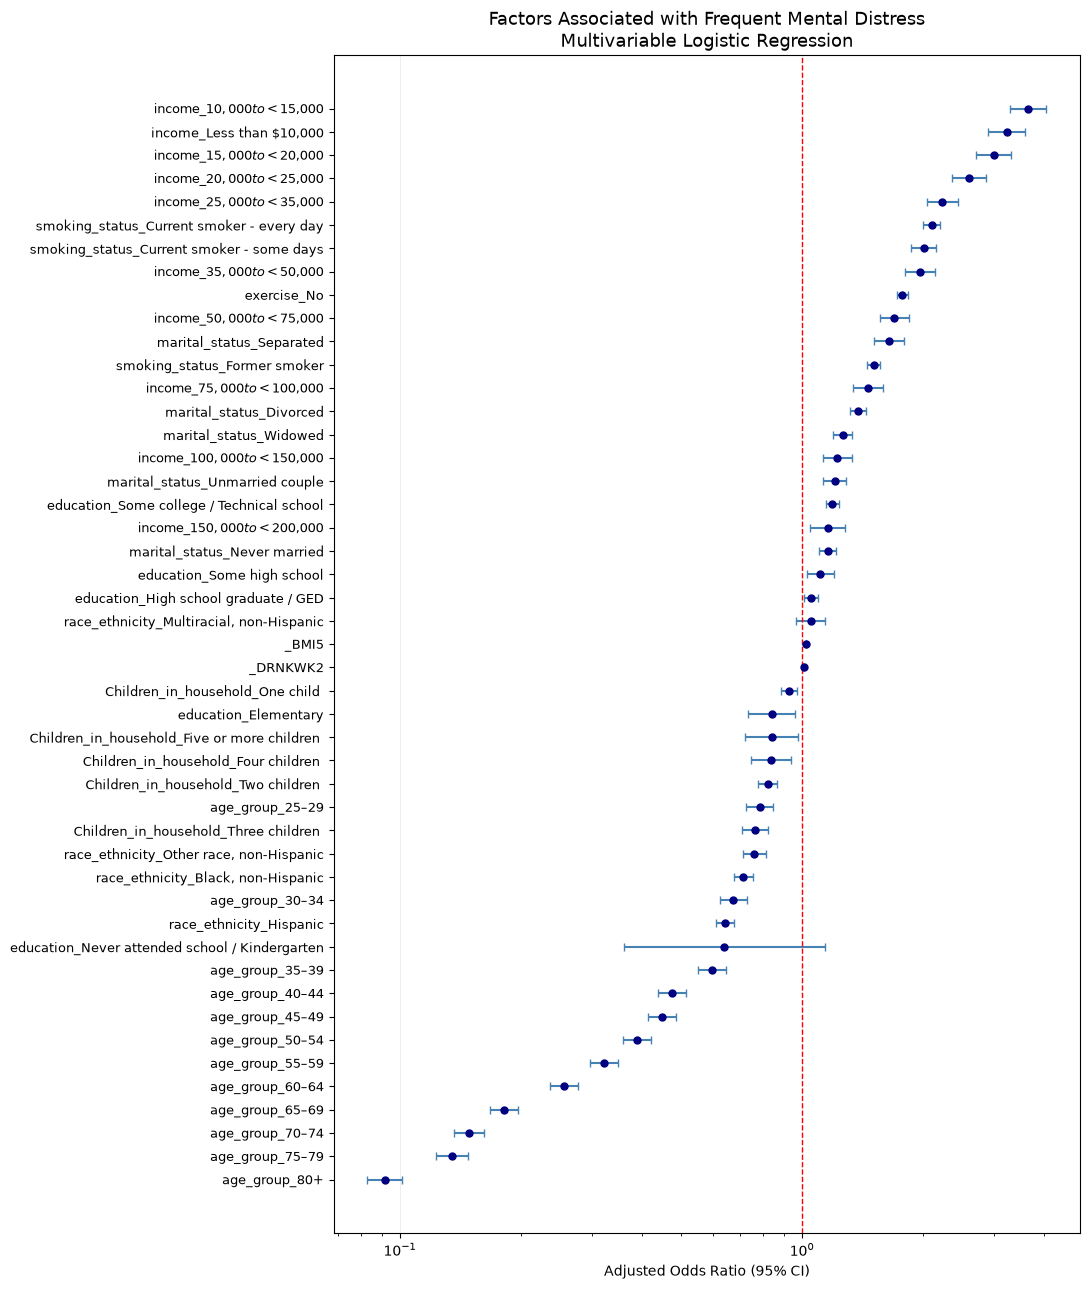

In [422]:

import matplotlib.pyplot as plt
import numpy as np

# Use the odds ratios already calculated in your notebook
plot_data = or_table.sort_values("Odds Ratio").copy()

fig, ax = plt.subplots(figsize=(11, 13))
y_pos = np.arange(len(plot_data))

# Plot adjusted odds ratios and 95% confidence intervals
ax.errorbar(
    plot_data["Odds Ratio"],
    y_pos,
    xerr=[
        plot_data["Odds Ratio"] - plot_data["CI Lower"],
        plot_data["CI Upper"] - plot_data["Odds Ratio"]
    ],
    fmt="o",
    color="navy",
    ecolor="steelblue",
    capsize=3,
    markersize=5
)

# Reference line: odds ratio = 1
ax.axvline(1, color="red", linestyle="--", linewidth=1)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data.index, fontsize=9)
ax.set_xscale("log")

ax.set_xlabel("Adjusted Odds Ratio (95% CI)")
ax.set_title(
    "Factors Associated with Frequent Mental Distress\n"
    "Multivariable Logistic Regression",
    fontsize=13
)

ax.grid(axis="x", alpha=0.2)
plt.tight_layout()

# Save the figure for Google Sites
plt.savefig(
    "Outputs/logistic_regression_forest_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of the Forest Plot

##### The forest plot presents the adjusted odds ratios (ORs) and their 95% confidence intervals (CIs) from the multivariable logistic regression examining factors associated with frequent mental distress among women.

##### - **OR > 1:** Indicates higher odds of frequent mental distress compared with the reference category.
##### - **OR < 1:** Indicates lower odds compared with the reference category.
##### - **OR = 1:** Indicates no difference in odds.
##### - **Horizontal lines:** Represent the 95% confidence intervals.
##### - **Red dashed line:** Represents an odds ratio of 1 (no association).

##### Confidence intervals that do not cross 1 indicate statistically significant associations at the 5% level under the model's assumptions.

##### These results represent adjusted associations rather than causal relationships. Because the analysis did not account for the BRFSS complex survey design, statistical significance should be interpreted cautiously.

In [423]:
not_significant = or_table[
    or_table["P-value"] >= 0.05
]

print("Number of non significant coefficients", len(not_significant))
print(not_significant.round(3).to_string())

Number of non significant coefficients 2
                                                Odds Ratio  CI Lower  CI Upper  P-value
race_ethnicity_Multiracial, non-Hispanic             1.049     0.965     1.141    0.257
education_Never attended school / Kindergarten       0.639     0.360     1.137    0.128


#### Interpretation: Both confidence intervals included 1, consistent with their p-values exceeding 0.05. These results do not establish the absence of an association. Furthermore, the significance of individual category comparisons does not determine the overall significance of a categorical predictor.

In [424]:

from sklearn.metrics import roc_auc_score

# Predict probabilities using the fitted logistic regression
predicted_probabilities = logit_results.predict(X)

# Calculate ROC-AUC
auc = roc_auc_score(y, predicted_probabilities)

print("ROC-AUC (training data):", round(auc, 3))


ROC-AUC (training data): 0.727


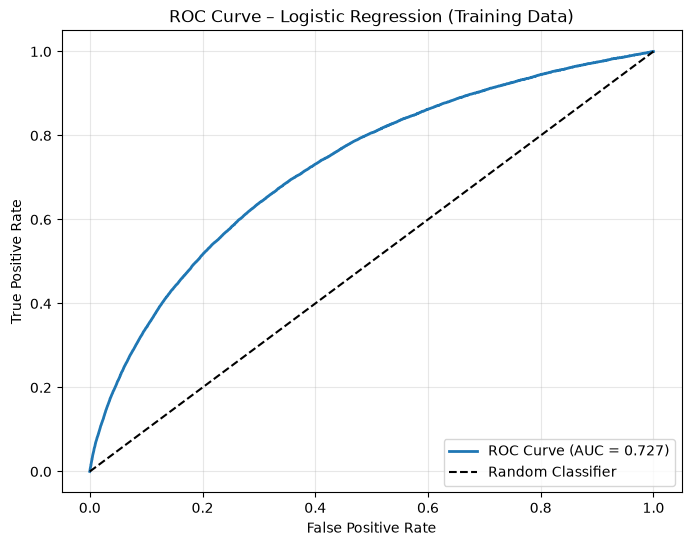

In [425]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y, predicted_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Logistic Regression (Training Data)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

##### The logistic regression model achieved a training ROC-AUC of 0.727, indicating moderate discrimination between women with and without frequent mental distress. Performance was evaluated on training data only.

## Key Findings and Conclusion


##### The analysis identified several patterns in women's self-reported health:

##### Income: Higher income was associated with better general health.

##### Age: Older women tended to report poorer general health but fewer poor mental-health days.

##### Exercise: Women reporting no exercise had 77.4% higher adjusted odds of frequent mental distress.

##### Smoking: Daily smokers had approximately 2.10 times the adjusted odds of frequent mental distress compared with never smokers.

##### Mental health model: The logistic regression achieved a training ROC-AUC of 0.727, indicating moderate discrimination in the analyzed sample.

### Limitations

##### The analysis was exploratory and unweighted. It did not account for the BRFSS complex survey design, and missing data reduced the regression sample to 153,742 observations. The findings describe associations, not causal effects. Model performance was assessed on training data only.


### Conclusion

##### Socioeconomic and lifestyle characteristics showed measurable associations with women's health. Importantly, general health and mental health displayed different patterns across age groups, highlighting the value of examining these outcomes separately.